## Entrenamiento y comparación de modelos

El notebook debe entrenar y comparar dos modelos principales:

| Modelo | Características | Obligatorio |
|---|---|---|
| **CNN propia** | Arquitectura construida desde cero | ✅ Sí |
| **MobileNetV2** | Transfer Learning | ✅ Sí |
| **CNN de larvas** | Clasificación microscópica | Opcional |

### Clases de clasificación

Ambos modelos principales identificarán las siguientes especies:

1. **Aedes aegypti**
2. **Aedes albopictus**
3. **Culex**

### Métrica principal

La métrica principal para evaluar y comparar los modelos será:

**F1-score macro ≥ 0,85**

### Métricas adicionales

También se deberán calcular las siguientes métricas:

1. **Accuracy**
2. **Precision por clase**
3. **Recall por clase**
4. **F1-score por clase**
5. **Matriz de confusión**
6. **Curvas de entrenamiento y validación**

### Importancia del F1-score macro

El **F1-score macro** es especialmente importante porque evita que una buena clasificación de las clases mayoritarias oculte malos resultados en **Aedes aegypti**.

Esta métrica calcula el promedio del F1-score de todas las clases, asignando el mismo peso a cada una, independientemente de la cantidad de imágenes disponibles.

Por lo tanto, el **F1-score macro ≥ 0,85** será el criterio principal para evaluar y comparar el rendimiento de la **CNN propia** y **MobileNetV2**.
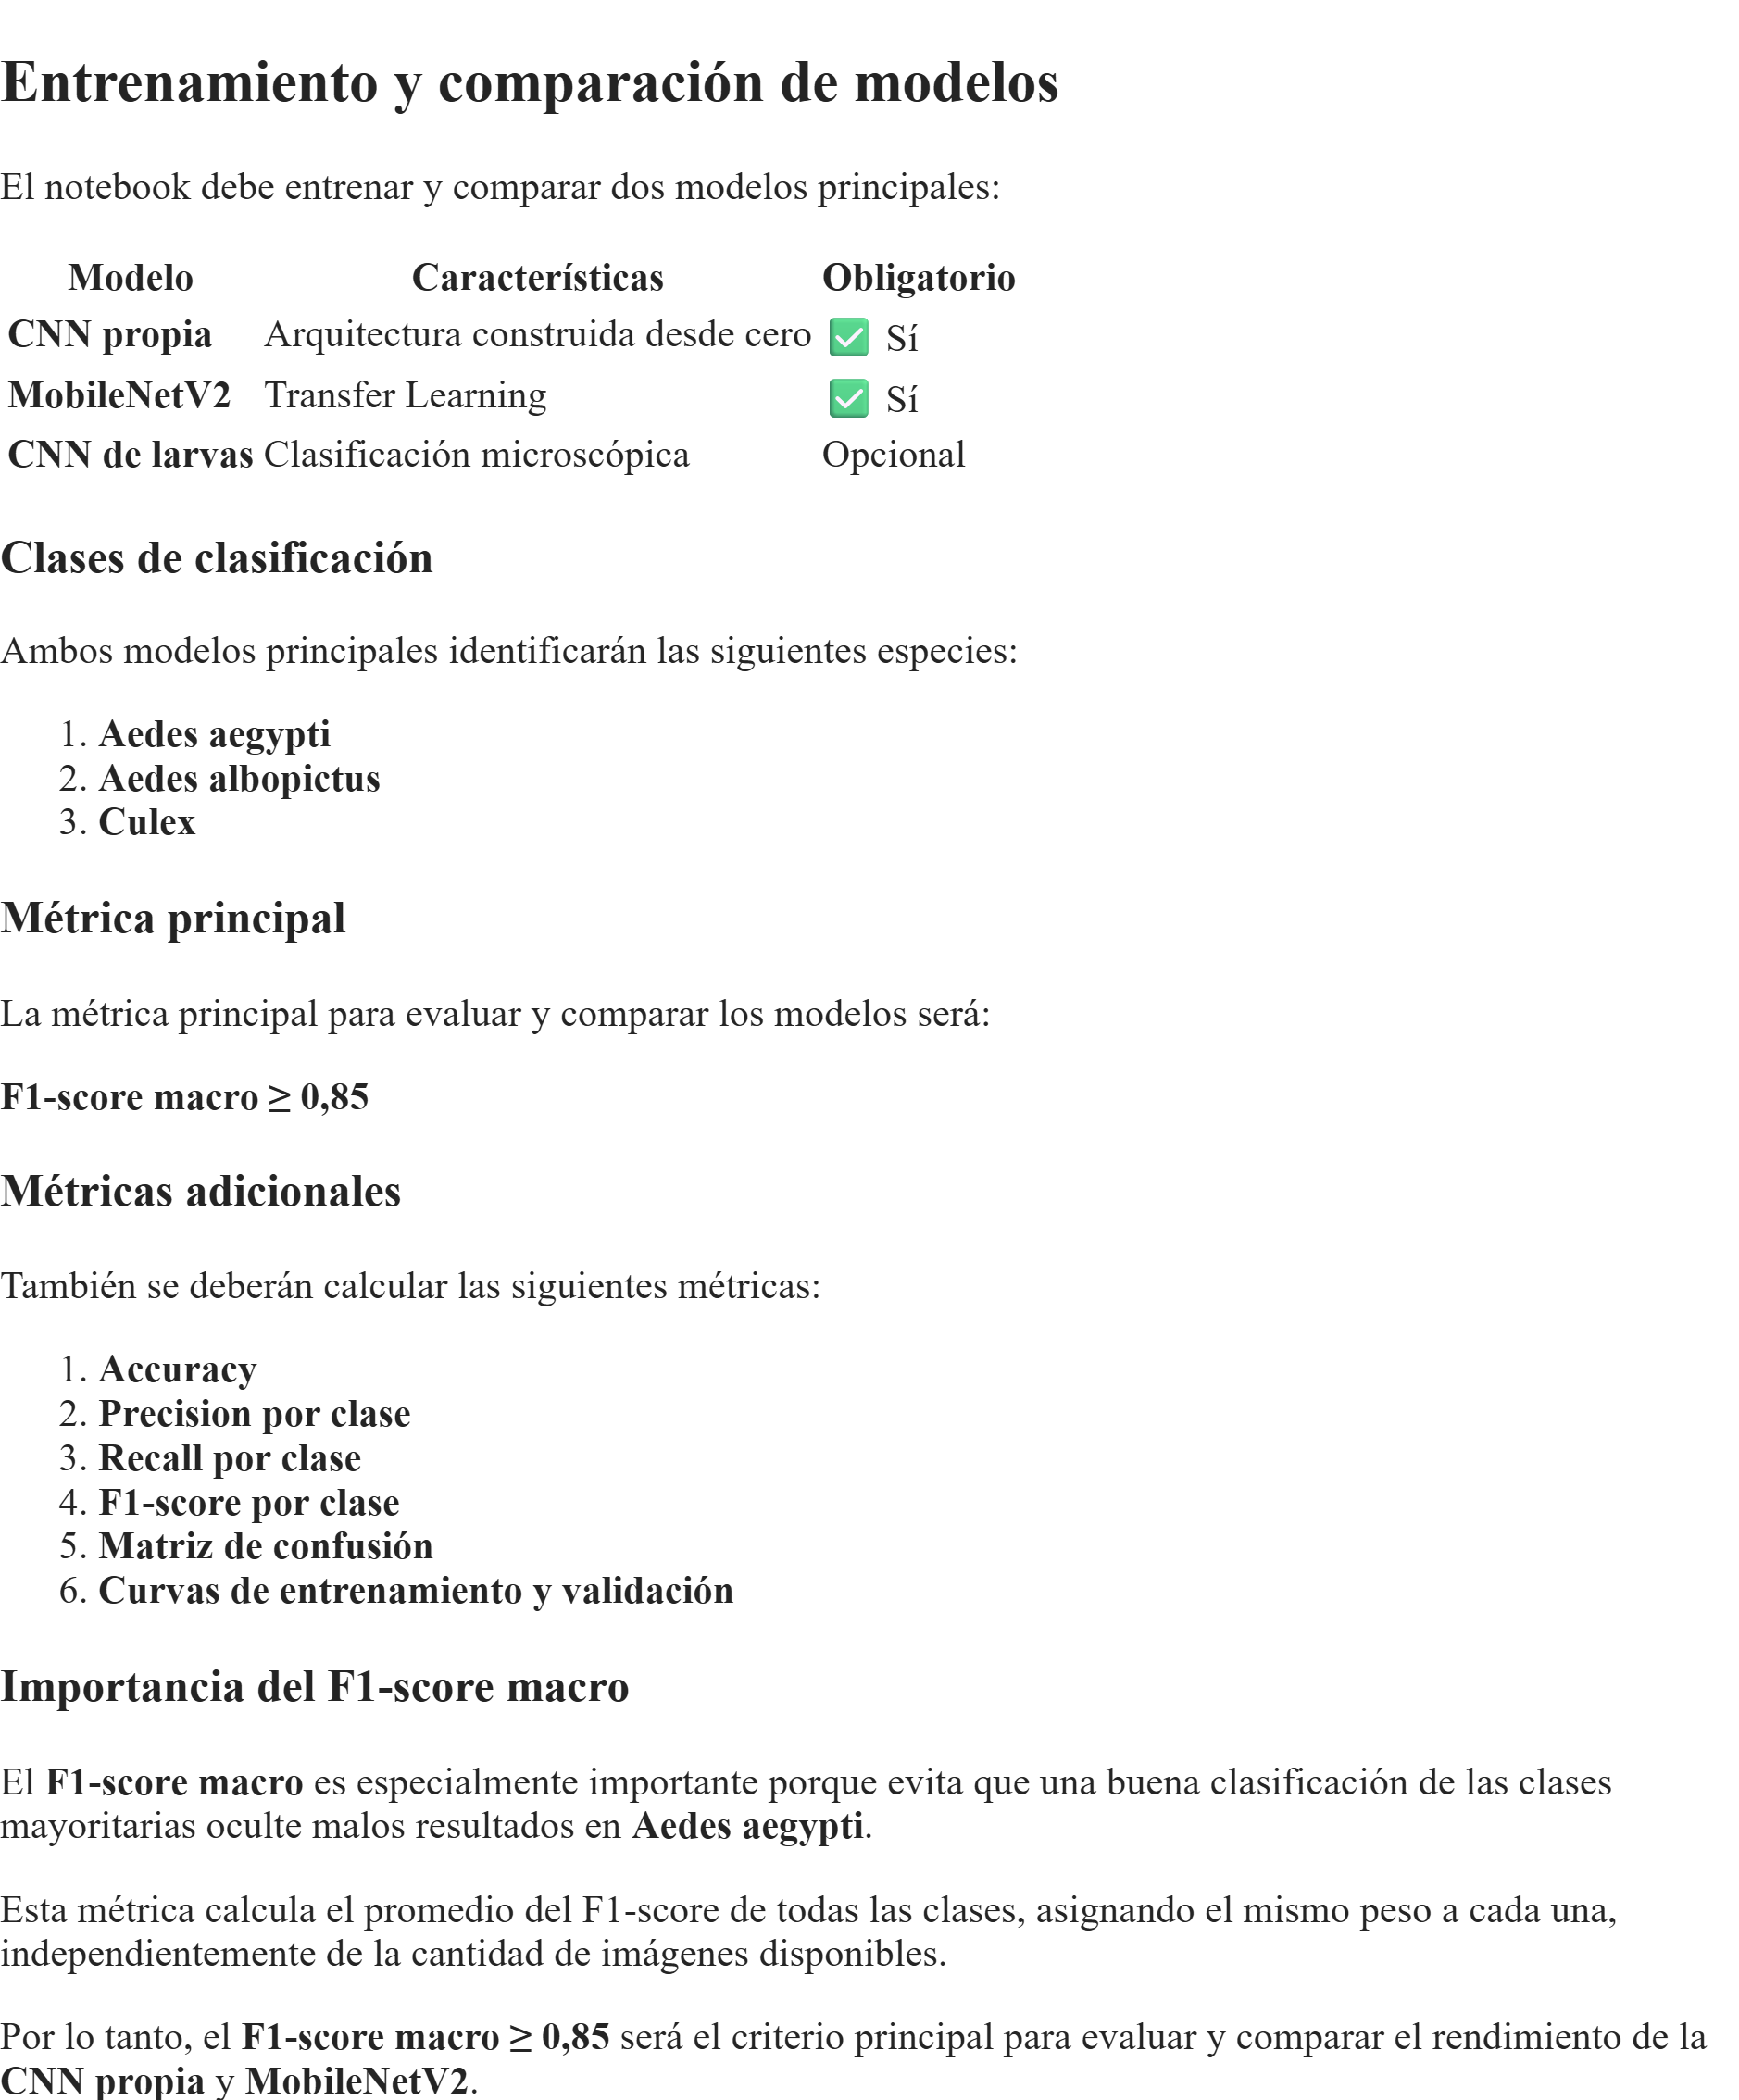
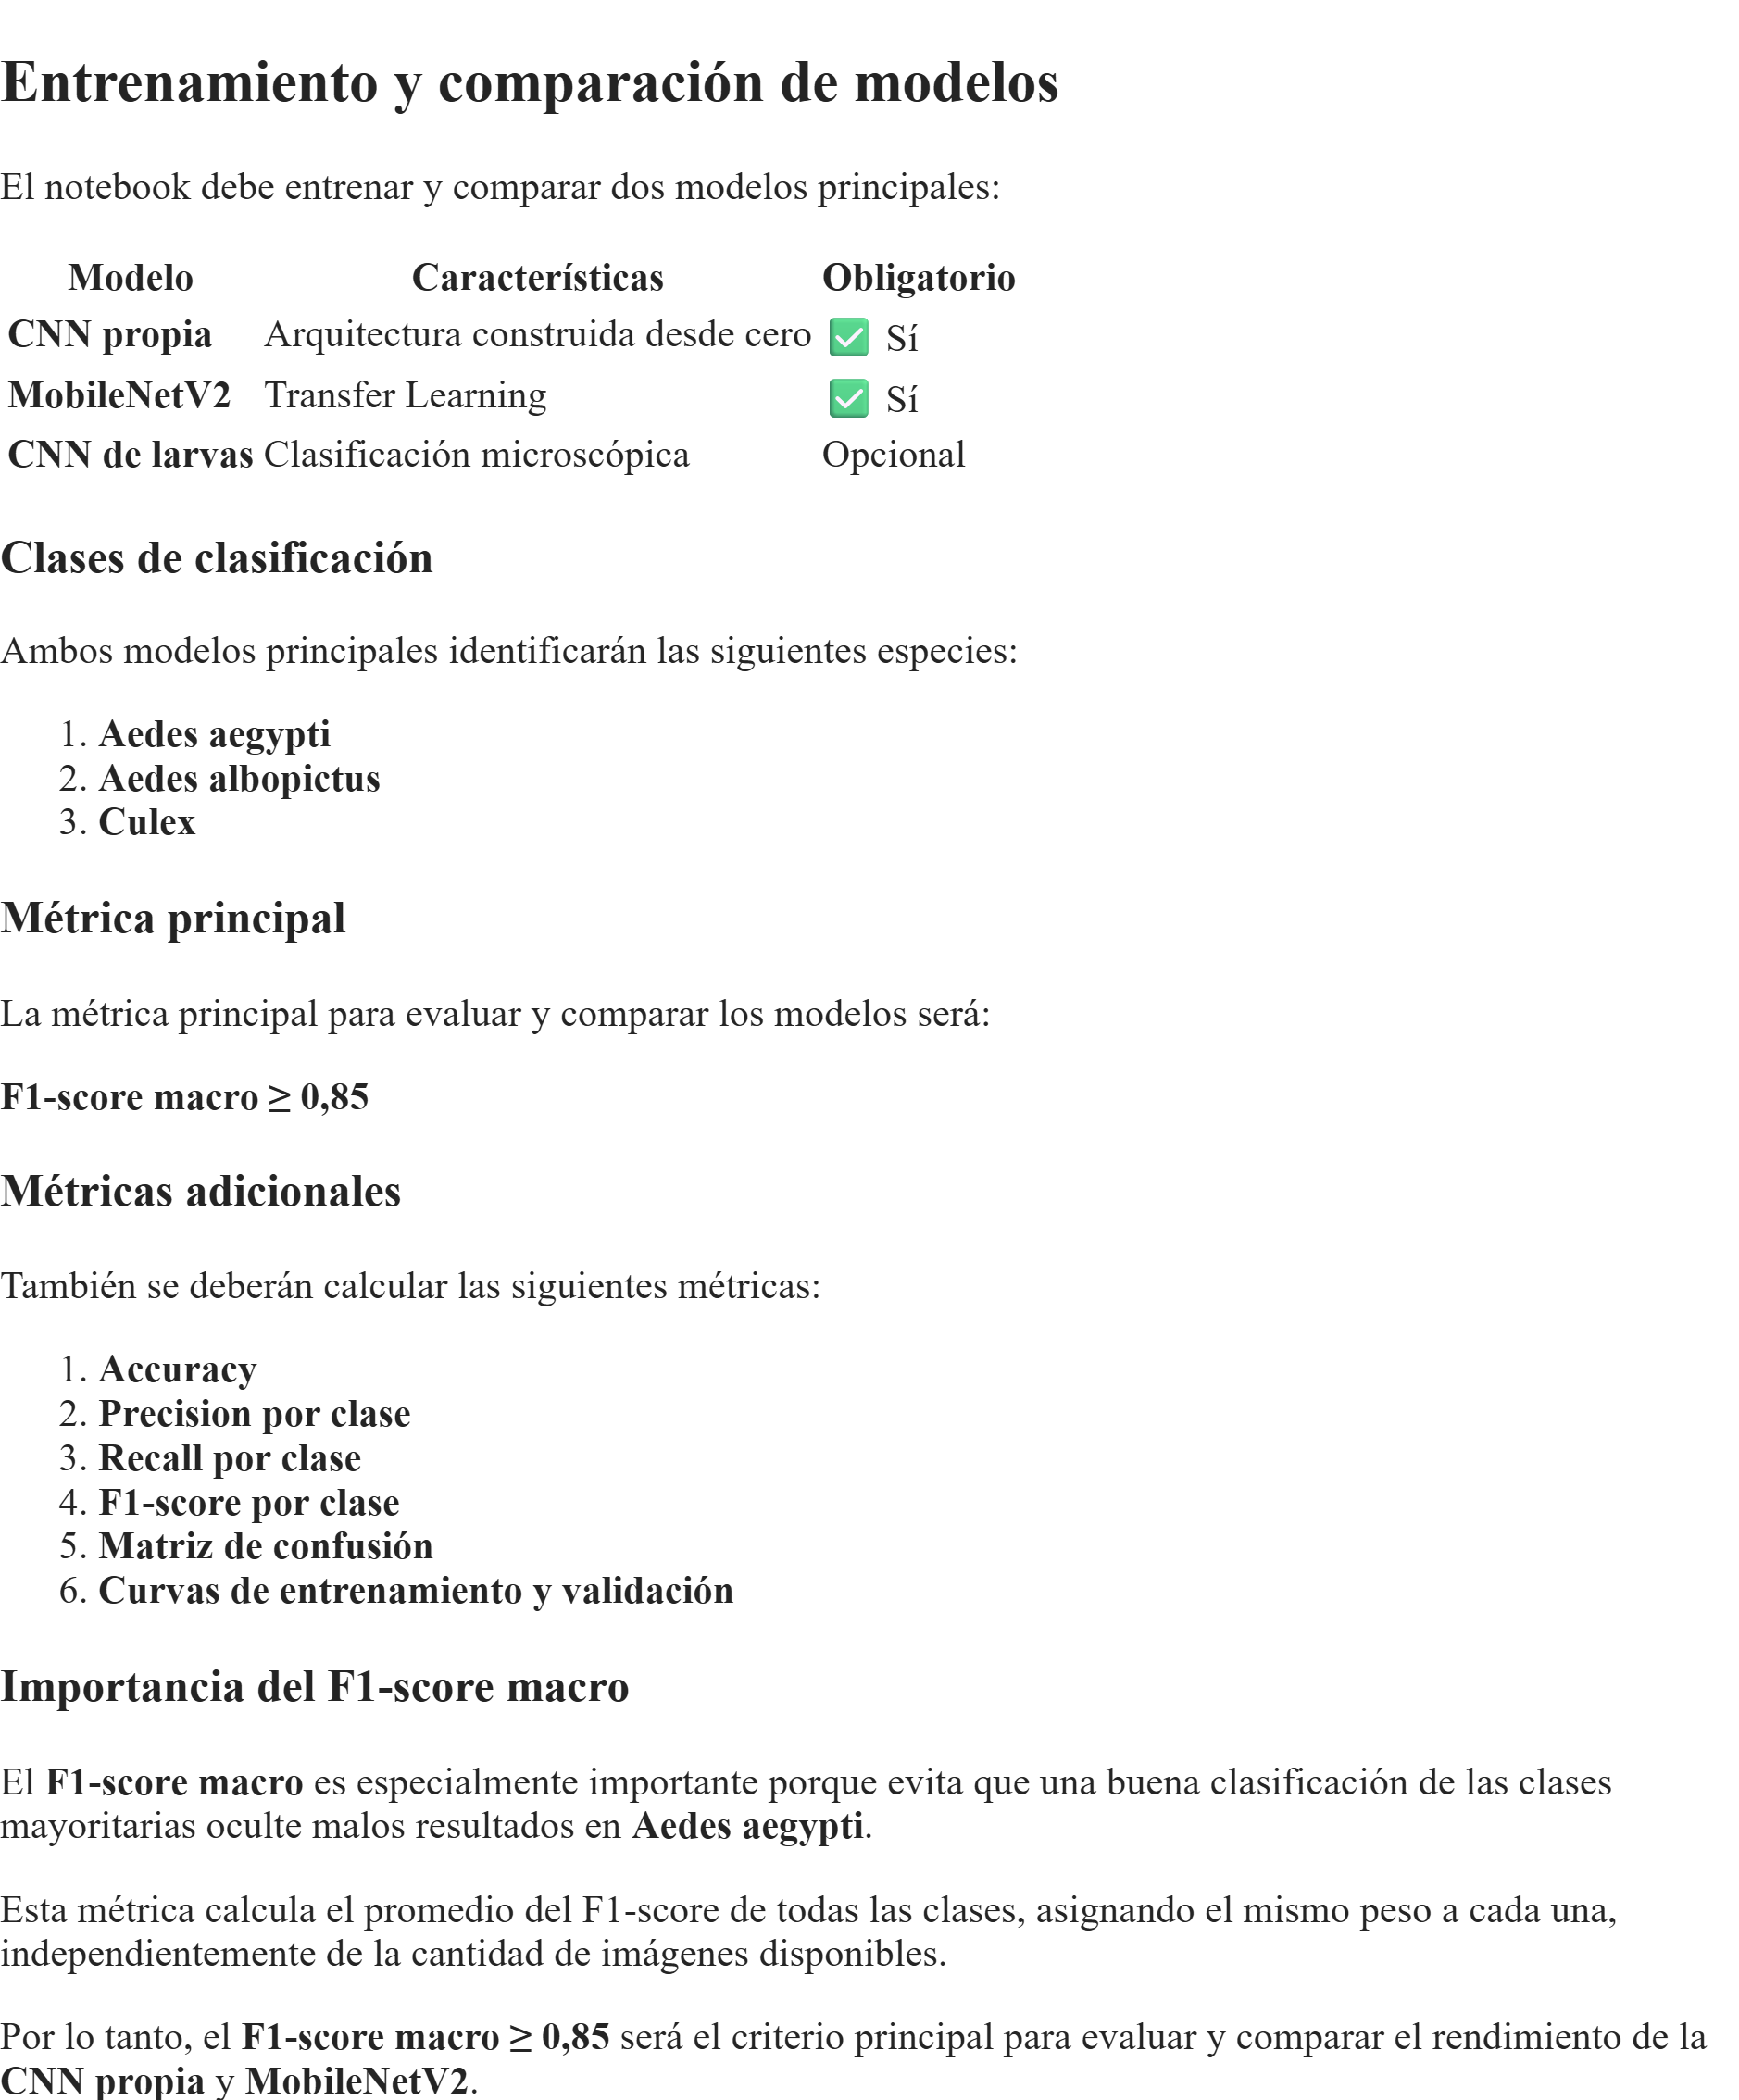

In [4]:
from pathlib import Path
import os
import random
import hashlib
import json
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import cv2

from PIL import Image, ImageOps

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import (
    train_test_split,
    StratifiedGroupKFold
)

from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


## CONFIGURACIÓN
### Definir parámetros generales

In [19]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

IMG_HEIGHT = 128
IMG_WIDTH = 128
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

BATCH_SIZE = 32

EPOCHS_CNN = 50
EPOCHS_MOBILENET = 30

CLASES = [
    "Aedes aegypti",
    "Aedes albopictus",
    "Culex"
]

NUM_CLASES = len(CLASES)

CLASS_TO_ID = {
    clase: indice
    for indice, clase in enumerate(CLASES)
}

ID_TO_CLASS = {
    indice: clase
    for clase, indice in CLASS_TO_ID.items()
}

print("Semilla:", SEED)
print("Tamaño de imagen:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Clases:", CLASS_TO_ID)

Semilla: 42
Tamaño de imagen: (128, 128)
Batch size: 32
Clases: {'Aedes aegypti': 0, 'Aedes albopictus': 1, 'Culex': 2}


## Rutas generales del proyecto

In [20]:
PROYECTO = Path(r"C:\VectorAI\VectorIA")

RAW = PROYECTO / "data" / "raw"
PROCESSED = PROYECTO / "data" / "processed" / "cnn"
MODELS = PROYECTO / "models"

PROCESSED.mkdir(
    parents=True,
    exist_ok=True
)

MODELS.mkdir(
    parents=True,
    exist_ok=True
)

print("Proyecto:", PROYECTO)
print("Datos originales:", RAW)
print("Datos procesados:", PROCESSED)
print("Modelos:", MODELS)

assert PROYECTO.is_dir(), (
    f"No existe la carpeta del proyecto: {PROYECTO}"
)

assert RAW.is_dir(), (
    f"No existe la carpeta de datos originales: {RAW}"
)

Proyecto: C:\VectorAI\VectorIA
Datos originales: C:\VectorAI\VectorIA\data\raw
Datos procesados: C:\VectorAI\VectorIA\data\processed\cnn
Modelos: C:\VectorAI\VectorIA\models


## Inspeccionar Data raw

In [21]:
print("Contenido de RAW:\n")

for elemento in sorted(RAW.iterdir()):
    tipo = "CARPETA" if elemento.is_dir() else "ARCHIVO"
    print(f"[{tipo}] {elemento.name}")

Contenido de RAW:

[CARPETA] Dataset of Vector Mosquito Images
[CARPETA] kaggle
[CARPETA] MLMI-2024 (Mosquito Larvae Microscopic Images)
[CARPETA] Mosquito Dataset Augmented
[CARPETA] mosquito_dataset_ai_v1


## Rutas de los DataSets


In [22]:
RUTA_IEEE = (
    RAW
    / "Mosquito Dataset Augmented"
)

RUTA_MENDELEY = (
    RAW
    / "Dataset of Vector Mosquito Images"
)

RUTA_MOSQUITO_ALERT = (
    RAW
    / "mosquito_dataset_ai_v1"
)

RUTA_KAGGLE = (
    RAW
    / "kaggle"
)

RUTAS_DATASETS = {
    "IEEE": RUTA_IEEE,
    "Mendeley": RUTA_MENDELEY,
    "Mosquito Alert": RUTA_MOSQUITO_ALERT,
    "Kaggle": RUTA_KAGGLE
}

for nombre, ruta_dataset in RUTAS_DATASETS.items():
    print(
        f"{nombre:17} | "
        f"Existe: {ruta_dataset.exists()} | "
        f"Es carpeta: {ruta_dataset.is_dir()} | "
        f"{ruta_dataset}"
    )

IEEE              | Existe: True | Es carpeta: True | C:\VectorAI\VectorIA\data\raw\Mosquito Dataset Augmented
Mendeley          | Existe: True | Es carpeta: True | C:\VectorAI\VectorIA\data\raw\Dataset of Vector Mosquito Images
Mosquito Alert    | Existe: True | Es carpeta: True | C:\VectorAI\VectorIA\data\raw\mosquito_dataset_ai_v1
Kaggle            | Existe: True | Es carpeta: True | C:\VectorAI\VectorIA\data\raw\kaggle


In [23]:
rutas_faltantes = {
    nombre: ruta
    for nombre, ruta in RUTAS_DATASETS.items()
    if not ruta.is_dir()
}

if rutas_faltantes:
    for nombre, ruta in rutas_faltantes.items():
        print(f"Ruta faltante para {nombre}: {ruta}")

    raise FileNotFoundError(
        "Una o más rutas de datasets no existen."
    )

print("\nTodas las rutas principales existen.")


Todas las rutas principales existen.


## Extensiones y mapeo de clases

In [24]:
EXTENSIONES_IMAGEN = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
    ".bmp",
    ".tif",
    ".tiff"
}

MAPEO_CLASES = {
    # IEEE
    "aedes": "Aedes aegypti",
    "culex": "Culex",

    # Mendeley
    "aedes aegypti": "Aedes aegypti",
    "culex quinquefasciatus": "Culex",

    # Mosquito Alert
    "aegypti": "Aedes aegypti",
    "albopictus": "Aedes albopictus",

    # Variantes posibles
    "aedes albopictus": "Aedes albopictus"
}

print("Extensiones permitidas:", EXTENSIONES_IMAGEN)
print("\nMapeo de clases:")

for etiqueta_original, etiqueta_final in MAPEO_CLASES.items():
    print(
        f"{etiqueta_original:25} -> {etiqueta_final}"
    )

Extensiones permitidas: {'.png', '.jpeg', '.jpg', '.tif', '.tiff', '.webp', '.bmp'}

Mapeo de clases:
aedes                     -> Aedes aegypti
culex                     -> Culex
aedes aegypti             -> Aedes aegypti
culex quinquefasciatus    -> Culex
aegypti                   -> Aedes aegypti
albopictus                -> Aedes albopictus
aedes albopictus          -> Aedes albopictus


Las etiquetas no incluidas, como Anopheles, Culiseta y Aedes japonicus/koreicus, quedarán excluidas.

## Funció para Listar Imágenes


In [8]:
def listar_imagenes(carpeta):
    """
    Devuelve las rutas únicas de todas las imágenes
    encontradas dentro de una carpeta.
    """
    carpeta = Path(carpeta)

    if not carpeta.is_dir():
        return []

    imagenes = {
        archivo.resolve()
        for archivo in carpeta.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower() in EXTENSIONES_IMAGEN
    }

    return sorted(
        imagenes,
        key=lambda ruta: str(ruta).lower()
    )

### Clases excluidas
No incluiremos:
Anopheles.
Culiseta.
Aedes japonicus/koreicus.
Anopheles stephensi.
Estas especies no pertenecen a las tres clases objetivo.

In [26]:
def listar_imagenes(carpeta):
    """
    Devuelve las rutas únicas de todas las imágenes
    encontradas dentro de una carpeta.
    """
    carpeta = Path(carpeta)

    if not carpeta.is_dir():
        return []

    imagenes = {
        archivo.resolve()
        for archivo in carpeta.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower() in EXTENSIONES_IMAGEN
    }

    return sorted(
        imagenes,
        key=lambda ruta: str(ruta).lower()
    )

In [27]:
for nombre, ruta_dataset in RUTAS_DATASETS.items():
    cantidad = len(
        listar_imagenes(ruta_dataset)
    )

    print(
        f"{nombre:17}: "
        f"{cantidad:,} archivos de imagen"
    )

IEEE             : 1,404 archivos de imagen
Mendeley         : 2,684 archivos de imagen
Mosquito Alert   : 10,357 archivos de imagen
Kaggle           : 2,462 archivos de imagen


## Inspeccionar nombres de carpetas

In [28]:
def obtener_carpetas_unicas(ruta_dataset):
    ruta_dataset = Path(ruta_dataset)

    carpetas = {
        carpeta.name
        for carpeta in ruta_dataset.rglob("*")
        if carpeta.is_dir()
    }

    return sorted(
        carpetas,
        key=str.lower
    )


for nombre, ruta_dataset in RUTAS_DATASETS.items():
    print("\n" + "=" * 60)
    print(nombre)
    print("=" * 60)

    carpetas = obtener_carpetas_unicas(
        ruta_dataset
    )

    for carpeta in carpetas[:50]:
        print(carpeta)

    if len(carpetas) > 50:
        print(
            f"... y {len(carpetas) - 50} carpetas adicionales"
        )


IEEE
Aedes
Culex

Mendeley
Aedes Aegypti
Anopheles Stephensi
Culex Quinquefasciatus
Mosquito Images Augmented
Mosquito Images Original
Original Images Mendeley

Mosquito Alert
images
labels

Kaggle
aegypti
aegypti_0
aegypti_0_testing
aegypti_180
aegypti_180_testing
aegypti_270
aegypti_270_testing
aegypti_90
aegypti_90_testing
albopictus
albopictus_0


## Iniciar el Inventario

In [44]:
registros = []
errores_inventario = []

## Función para registrar imágenes

In [45]:
def registrar_imagen(
    filepath,
    source_dataset,
    original_label,
    bbox=None,
    bbox_valid=None,
    group_id=None
):
    filepath = Path(filepath)

    if not filepath.is_file():
        errores_inventario.append({
            "source_dataset": source_dataset,
            "filepath": str(filepath),
            "error": "El archivo no existe"
        })

        return False

    if filepath.suffix.lower() not in EXTENSIONES_IMAGEN:
        errores_inventario.append({
            "source_dataset": source_dataset,
            "filepath": str(filepath),
            "error": "Extensión no admitida"
        })

        return False

    original_label_normalized = (
        str(original_label)
        .strip()
        .lower()
    )

    class_name = MAPEO_CLASES.get(
        original_label_normalized
    )

    if class_name is None:
        return False

    bbox_x1 = np.nan
    bbox_y1 = np.nan
    bbox_x2 = np.nan
    bbox_y2 = np.nan

    if bbox is not None:
        if len(bbox) != 4:
            errores_inventario.append({
                "source_dataset": source_dataset,
                "filepath": str(filepath),
                "error": f"Bounding box inválida: {bbox}"
            })

            return False

        bbox_x1 = int(bbox[0])
        bbox_y1 = int(bbox[1])
        bbox_x2 = int(bbox[2])
        bbox_y2 = int(bbox[3])

    if bbox_valid is None:
        bbox_valid = bbox is not None

    if group_id is None:
        group_id = (
            f"{source_dataset}_{filepath.stem}"
        )

    registros.append({
        "filepath": str(filepath.resolve()),
        "filename": filepath.name,
        "extension": filepath.suffix.lower(),
        "source_dataset": source_dataset,
        "original_label": str(original_label),
        "original_label_normalized": (
            original_label_normalized
        ),
        "class_name": class_name,
        "class_id": CLASS_TO_ID[class_name],
        "group_id": str(group_id),
        "bbox_x1": bbox_x1,
        "bbox_y1": bbox_y1,
        "bbox_x2": bbox_x2,
        "bbox_y2": bbox_y2,
        "has_bbox": bbox is not None,
        "bbox_valid": bool(bbox_valid)
    })

    return True

## Cargador IEEE

In [46]:
def cargar_ieee(ruta_ieee):
    ruta_ieee = Path(ruta_ieee)

    if not ruta_ieee.is_dir():
        raise FileNotFoundError(
            f"No existe IEEE: {ruta_ieee}"
        )

    conteos = {
        "Aedes": 0,
        "Culex": 0
    }

    sin_clase = []

    for archivo in listar_imagenes(ruta_ieee):
        partes = [
            parte.lower()
            for parte in archivo.parts
        ]

        if any(
            "culex" in parte
            for parte in partes
        ):
            etiqueta = "Culex"

        elif any(
            "aedes" in parte
            for parte in partes
        ):
            etiqueta = "Aedes"

        else:
            sin_clase.append(str(archivo))
            continue

        agregado = registrar_imagen(
            filepath=archivo,
            source_dataset="IEEE",
            original_label=etiqueta,
            group_id=f"IEEE_{archivo.stem}"
        )

        if agregado:
            conteos[etiqueta] += 1

    print("\nIEEE")
    print(
        "Aedes -> Aedes aegypti:",
        conteos["Aedes"]
    )
    print("Culex:", conteos["Culex"])
    print("Total útil:", sum(conteos.values()))
    print("Imágenes sin identificar:", len(sin_clase))

    return {
        "conteos": conteos,
        "sin_clase": sin_clase
    }

In [47]:
registros.clear()
errores_inventario.clear()

resultado_ieee = cargar_ieee(
    RUTA_IEEE
)

print(
    "\nRegistros después de IEEE:",
    len(registros)
)


IEEE
Aedes -> Aedes aegypti: 810
Culex: 594
Total útil: 1404
Imágenes sin identificar: 0

Registros después de IEEE: 1404


## Cargador Mendeley

In [48]:
def cargar_mendeley(ruta_mendeley):
    """
    Carga únicamente las imágenes originales de Mendeley.

    Excluye:
    - Mosquito Images Augmented
    - Anopheles stephensi

    Incluye:
    - Aedes aegypti
    - Culex quinquefasciatus
    """

    ruta_mendeley = Path(ruta_mendeley)

    if not ruta_mendeley.is_dir():
        raise FileNotFoundError(
            f"No existe Mendeley: {ruta_mendeley}"
        )

    # Carpeta que contiene las fotografías originales.
    carpeta_originales = (
        ruta_mendeley
        / "Mosquito Images Original"
        / "Original Images Mendeley"
    )

    if not carpeta_originales.is_dir():
        raise FileNotFoundError(
            "No se encontró la carpeta de imágenes originales: "
            f"{carpeta_originales}"
        )

    configuracion = {
        "Aedes Aegypti": "Aedes aegypti",
        "Culex Quinquefasciatus": "Culex quinquefasciatus"
    }

    conteos = {
        "Aedes aegypti": 0,
        "Culex quinquefasciatus": 0
    }

    for nombre_carpeta, etiqueta in configuracion.items():

        carpeta_especie = (
            carpeta_originales
            / nombre_carpeta
        )

        if not carpeta_especie.is_dir():
            raise FileNotFoundError(
                f"No existe la carpeta: {carpeta_especie}"
            )

        imagenes = listar_imagenes(
            carpeta_especie
        )

        for archivo in imagenes:

            agregado = registrar_imagen(
                filepath=archivo,
                source_dataset="Mendeley",
                original_label=etiqueta,
                group_id=f"Mendeley_{archivo.stem}"
            )

            if agregado:
                conteos[etiqueta] += 1

    total = sum(conteos.values())

    print("\nMENDELEY - IMÁGENES ORIGINALES")
    print("=" * 45)

    print(
        "Aedes aegypti:",
        conteos["Aedes aegypti"]
    )

    print(
        "Culex quinquefasciatus:",
        conteos["Culex quinquefasciatus"]
    )

    print("Total útil:", total)

    print(
        "Imágenes aumentadas:",
        "excluidas del inventario"
    )

    return {
        "conteos": conteos,
        "total": total,
        "tipo": "originales"
    }

In [54]:
# Reiniciar el inventario temporal.
registros.clear()
errores_inventario.clear()

# Cargar IEEE.
resultado_ieee = cargar_ieee(
    RUTA_IEEE
)

# Cargar únicamente originales de Mendeley.
resultado_mendeley = cargar_mendeley(
    RUTA_MENDELEY
)

print("\n" + "=" * 50)
print("RESUMEN ACUMULADO")
print("=" * 50)

print(
    "Registros IEEE + Mendeley:",
    len(registros)
)


IEEE
Aedes -> Aedes aegypti: 810
Culex: 594
Total útil: 1404
Imágenes sin identificar: 0

MENDELEY - IMÁGENES ORIGINALES
Aedes aegypti: 15
Culex quinquefasciatus: 20
Total útil: 35
Imágenes aumentadas: excluidas del inventario

RESUMEN ACUMULADO
Registros IEEE + Mendeley: 1439


In [55]:
df_temporal = pd.DataFrame(registros)

print("DISTRIBUCIÓN ACTUAL")
print("=" * 50)

display(
    pd.crosstab(
        df_temporal["source_dataset"],
        df_temporal["class_name"]
    )
)

# Verificar que no se hayan incluido imágenes aumentadas.
mendeley_registros = df_temporal[
    df_temporal["source_dataset"] == "Mendeley"
]

rutas_aumentadas = (
    mendeley_registros["filepath"]
    .str.contains(
        "Mosquito Images Augmented",
        case=False,
        regex=False
    )
)

assert not rutas_aumentadas.any(), (
    "Se encontraron imágenes aumentadas de Mendeley."
)

assert len(mendeley_registros) == 35, (
    "Mendeley debería aportar 35 imágenes originales útiles."
)

print("\nValidación correcta:")
print("- Mendeley contiene 35 imágenes originales útiles.")
print("- No se incluyeron imágenes aumentadas.")

DISTRIBUCIÓN ACTUAL


class_name,Aedes aegypti,Culex
source_dataset,,
IEEE,810,594
Mendeley,15,20



Validación correcta:
- Mendeley contiene 35 imágenes originales útiles.
- No se incluyeron imágenes aumentadas.


In [57]:
# Limpiar únicamente el inventario temporal
registros.clear()
errores_inventario.clear()

# Volver a cargar IEEE
resultado_ieee = cargar_ieee(
    RUTA_IEEE
)

# Volver a cargar Mendeley
resultado_mendeley = cargar_mendeley(
    RUTA_MENDELEY
)

print("\n" + "=" * 50)
print("VALIDACIÓN FINAL")
print("=" * 50)

print("Total de registros:", len(registros))

assert len(registros) == 1439, (
    f"Se esperaban 1439 registros, "
    f"pero se encontraron {len(registros)}"
)

print("✅ IEEE y Mendeley cargados correctamente.")


IEEE
Aedes -> Aedes aegypti: 810
Culex: 594
Total útil: 1404
Imágenes sin identificar: 0

MENDELEY - IMÁGENES ORIGINALES
Aedes aegypti: 15
Culex quinquefasciatus: 20
Total útil: 35
Imágenes aumentadas: excluidas del inventario

VALIDACIÓN FINAL
Total de registros: 1439
✅ IEEE y Mendeley cargados correctamente.


In [58]:
df_temporal = pd.DataFrame(registros)

print("Total:", len(df_temporal))

print(
    "Rutas repetidas:",
    df_temporal["filepath"].duplicated().sum()
)

display(
    pd.crosstab(
        df_temporal["source_dataset"],
        df_temporal["class_name"]
    )
)

Total: 1439
Rutas repetidas: 0


class_name,Aedes aegypti,Culex
source_dataset,,
IEEE,810,594
Mendeley,15,20


## Buscar el archivo de anotaciones

In [59]:
def buscar_archivo_unico(carpeta_base, nombre_archivo):

    coincidencias = list(
        Path(carpeta_base).rglob(nombre_archivo)
    )

    if not coincidencias:
        raise FileNotFoundError(
            f"No se encontró {nombre_archivo} "
            f"dentro de {carpeta_base}"
        )

    if len(coincidencias) > 1:
        raise ValueError(
            f"Se encontraron varios archivos "
            f"{nombre_archivo}: {coincidencias}"
        )

    return coincidencias[0]


RUTA_ANNOTATIONS = buscar_archivo_unico(
    RUTA_MOSQUITO_ALERT,
    "annotations.csv"
)

print("Archivo encontrado:")
print(RUTA_ANNOTATIONS)

Archivo encontrado:
C:\VectorAI\VectorIA\data\raw\mosquito_dataset_ai_v1\labels\annotations.csv


## Inspeccionar las anotaciones

In [60]:
anotaciones = pd.read_csv(
    RUTA_ANNOTATIONS
)

print("Cantidad de anotaciones:", len(anotaciones))

print("\nColumnas encontradas:")
print(anotaciones.columns.tolist())

print("\nPrimeras 10 anotaciones:")
display(anotaciones.head(10))

print("\nDistribución de etiquetas:")
display(
    anotaciones["class_label"].value_counts()
)

Cantidad de anotaciones: 10357

Columnas encontradas:
['img_fName', 'img_w', 'img_h', 'bbx_xtl', 'bbx_ytl', 'bbx_xbr', 'bbx_ybr', 'class_label']

Primeras 10 anotaciones:


,img_fName,img_w,img_h,bbx_xtl,bbx_ytl,bbx_xbr,bbx_ybr,class_label
0,train_00000.jpeg,2448,3264,1301,1546,1641,2096,albopictus
1,train_00001.jpeg,3024,4032,900,1897,1950,2990,albopictus
2,train_00002.jpeg,768,1024,220,58,659,808,albopictus
3,train_00003.jpeg,3456,4608,1169,2364,1586,2826,albopictus
4,train_00004.jpeg,1024,1365,129,231,697,1007,culex
5,train_00005.jpeg,1152,2560,198,798,954,1351,albopictus
6,train_00006.jpeg,3072,4080,1104,1030,2458,2911,anopheles
7,train_00007.jpeg,2128,4608,248,728,2049,1992,albopictus
8,train_00008.jpeg,4000,2250,1768,899,2414,1591,albopictus
9,train_00009.jpeg,768,1024,180,140,683,744,albopictus



Distribución de etiquetas:


class_label
albopictus            4612
culex                 4563
culiseta               622
japonicus-koreicus     429
anopheles               84
aegypti                 47
Name: count, dtype: int64

## Crear el cargador de Mosquito Alert

Esta función:

Localiza la carpeta images.

Relaciona cada fotografía con su anotación.

Conserva las etiquetas.

Verifica las bounding boxes.

Registra únicamente las tres clases de VectorIA.

Reporta imágenes faltantes y cajas inválidas.


In [61]:
def cargar_mosquito_alert(ruta_mosquito_alert):

    ruta_mosquito_alert = Path(
        ruta_mosquito_alert
    )

    if not ruta_mosquito_alert.is_dir():
        raise FileNotFoundError(
            f"No existe Mosquito Alert: {ruta_mosquito_alert}"
        )

    csv_anotaciones = buscar_archivo_unico(
        ruta_mosquito_alert,
        "annotations.csv"
    )

    anotaciones = pd.read_csv(
        csv_anotaciones
    )

    columnas_requeridas = {
        "img_fName",
        "img_w",
        "img_h",
        "bbx_xtl",
        "bbx_ytl",
        "bbx_xbr",
        "bbx_ybr",
        "class_label"
    }

    faltantes = (
        columnas_requeridas
        - set(anotaciones.columns)
    )

    if faltantes:
        raise ValueError(
            f"Faltan columnas: {sorted(faltantes)}"
        )

    carpetas_images = [
        carpeta
        for carpeta in ruta_mosquito_alert.rglob("*")
        if carpeta.is_dir()
        and carpeta.name.lower() == "images"
    ]

    if len(carpetas_images) != 1:
        raise ValueError(
            "Se esperaba una sola carpeta images. "
            f"Encontradas: {carpetas_images}"
        )

    carpeta_images = carpetas_images[0]

    archivos_por_nombre = {}

    for archivo in listar_imagenes(carpeta_images):
        archivos_por_nombre.setdefault(
            archivo.name,
            []
        ).append(archivo)

    clases_utiles = {
        "aegypti",
        "albopictus",
        "culex"
    }

    conteos = {
        "aegypti": 0,
        "albopictus": 0,
        "culex": 0
    }

    sin_imagen = []
    nombres_ambiguos = []
    cajas_invalidas = []

    for _, fila in anotaciones.iterrows():

        etiqueta = str(
            fila["class_label"]
        ).strip().lower()

        if etiqueta not in clases_utiles:
            continue

        nombre_imagen = str(
            fila["img_fName"]
        ).strip()

        coincidencias = archivos_por_nombre.get(
            nombre_imagen,
            []
        )

        if len(coincidencias) == 0:
            sin_imagen.append(nombre_imagen)
            continue

        if len(coincidencias) > 1:
            nombres_ambiguos.append(nombre_imagen)
            continue

        archivo = coincidencias[0]

        coordenadas = [
            "bbx_xtl",
            "bbx_ytl",
            "bbx_xbr",
            "bbx_ybr",
            "img_w",
            "img_h"
        ]

        if fila[coordenadas].isna().any():
            cajas_invalidas.append({
                "filename": nombre_imagen,
                "motivo": "Coordenadas faltantes"
            })
            bbox = None
            bbox_valida = False

        else:
            x1 = int(fila["bbx_xtl"])
            y1 = int(fila["bbx_ytl"])
            x2 = int(fila["bbx_xbr"])
            y2 = int(fila["bbx_ybr"])

            ancho = int(fila["img_w"])
            alto = int(fila["img_h"])

            bbox_valida = (
                0 <= x1 < x2 <= ancho
                and
                0 <= y1 < y2 <= alto
            )

            if bbox_valida:
                bbox = (x1, y1, x2, y2)

            else:
                bbox = None

                cajas_invalidas.append({
                    "filename": nombre_imagen,
                    "class_label": etiqueta,
                    "img_w": ancho,
                    "img_h": alto,
                    "bbox_x1": x1,
                    "bbox_y1": y1,
                    "bbox_x2": x2,
                    "bbox_y2": y2
                })

        agregado = registrar_imagen(
            filepath=archivo,
            source_dataset="Mosquito Alert",
            original_label=etiqueta,
            bbox=bbox,
            bbox_valid=bbox_valida,
            group_id=f"MosquitoAlert_{archivo.stem}"
        )

        if agregado:
            conteos[etiqueta] += 1

    print("\nMOSQUITO ALERT")
    print("=" * 50)

    print("Aedes aegypti:", conteos["aegypti"])
    print("Aedes albopictus:", conteos["albopictus"])
    print("Culex:", conteos["culex"])

    print(
        "Total útil:",
        sum(conteos.values())
    )

    print(
        "Anotaciones sin imagen:",
        len(sin_imagen)
    )

    print(
        "Nombres ambiguos:",
        len(nombres_ambiguos)
    )

    print(
        "Cajas inválidas:",
        len(cajas_invalidas)
    )

    return {
        "conteos": conteos,
        "sin_imagen": sin_imagen,
        "nombres_ambiguos": nombres_ambiguos,
        "cajas_invalidas": cajas_invalidas
    }

## Ejecutar Mosquito Alert
#### verificaremos que tenemos las 1.439 imágenes correctas.

In [62]:
print("Registros antes de Mosquito Alert:", len(registros))

assert len(registros) == 1439, (
    "Antes de cargar Mosquito Alert deben existir "
    "1439 registros de IEEE y Mendeley."
)

resultado_mosquito_alert = cargar_mosquito_alert(
    RUTA_MOSQUITO_ALERT
)

print("\n" + "=" * 50)
print("RESUMEN ACUMULADO")
print("=" * 50)

print("Registros acumulados:", len(registros))

Registros antes de Mosquito Alert: 1439

MOSQUITO ALERT
Aedes aegypti: 47
Aedes albopictus: 4612
Culex: 4563
Total útil: 9222
Anotaciones sin imagen: 0
Nombres ambiguos: 0
Cajas inválidas: 3

RESUMEN ACUMULADO
Registros acumulados: 10661


#### Revisar las cajas inválidas

In [63]:
df_cajas_invalidas = pd.DataFrame(
    resultado_mosquito_alert["cajas_invalidas"]
)

print(
    "Cantidad de cajas inválidas:",
    len(df_cajas_invalidas)
)

if not df_cajas_invalidas.empty:
    display(df_cajas_invalidas)
else:
    print("No se encontraron cajas inválidas.")

Cantidad de cajas inválidas: 3


,filename,class_label,img_w,img_h,bbox_x1,bbox_y1,bbox_x2,bbox_y2
0,train_09004.jpeg,culex,1024,1365,435,233,1159,650
1,train_10156.jpeg,albopictus,1024,2272,1070,512,1312,845
2,train_10160.jpeg,culex,1816,4032,1755,522,2345,964


#### Verificar el inventario acumulado

In [64]:
df_temporal = pd.DataFrame(registros)

print("Total acumulado:", len(df_temporal))

print("\nDistribución por dataset:")

display(
    df_temporal["source_dataset"].value_counts()
)

print("\nDistribución por clase:")

display(
    pd.crosstab(
        df_temporal["source_dataset"],
        df_temporal["class_name"]
    )
)

print("\nRutas repetidas:")

print(
    df_temporal["filepath"].duplicated().sum()
)

Total acumulado: 10661

Distribución por dataset:


source_dataset
Mosquito Alert    9222
IEEE              1404
Mendeley            35
Name: count, dtype: int64


Distribución por clase:


class_name,Aedes aegypti,Aedes albopictus,Culex
source_dataset,,,
IEEE,810,0,594
Mendeley,15,0,20
Mosquito Alert,47,4612,4563



Rutas repetidas:
0


## Crear identificadores de grupo para Kaggle

In [65]:
def obtener_grupo_kaggle(nombre_archivo):

    stem = (
        Path(nombre_archivo)
        .stem
        .lower()
        .strip()
    )

    # Eliminar sufijos como " - Copy".
    stem = re.sub(
        r"\s*-\s*copy(?:\s*\(\d+\))?$",
        "",
        stem,
        flags=re.IGNORECASE
    )

    # Eliminar una letra final a, b, c o d
    # cuando aparece después de un número.
    stem = re.sub(
        r"(?<=\d)[a-d]$",
        "",
        stem
    )

    return stem

In [66]:
ejemplos = [
    "aegypti100a.jpg",
    "aegypti100b.jpg",
    "aegypti100c.jpg",
    "albopictus25d.jpg",
    "aegypti29b - Copy.jpg"
]

for nombre in ejemplos:
    print(
        nombre,
        "->",
        obtener_grupo_kaggle(nombre)
    )

aegypti100a.jpg -> aegypti100
aegypti100b.jpg -> aegypti100
aegypti100c.jpg -> aegypti100
albopictus25d.jpg -> albopictus25
aegypti29b - Copy.jpg -> aegypti29


## Crear el cargador de Kaggle

In [67]:
def cargar_kaggle(ruta_kaggle):

    ruta_kaggle = Path(ruta_kaggle)

    if not ruta_kaggle.is_dir():
        raise FileNotFoundError(
            f"No existe Kaggle: {ruta_kaggle}"
        )

    conteos = {
        "aegypti": 0,
        "albopictus": 0
    }

    sin_clase = []

    for archivo in listar_imagenes(ruta_kaggle):

        # Utilizar solamente las carpetas
        # relativas al dataset Kaggle.
        partes = [
            parte.strip().lower()
            for parte in archivo.relative_to(
                ruta_kaggle
            ).parts[:-1]
        ]

        if "albopictus" in partes:
            etiqueta = "albopictus"

        elif "aegypti" in partes:
            etiqueta = "aegypti"

        else:
            sin_clase.append(str(archivo))
            continue

        grupo_base = obtener_grupo_kaggle(
            archivo.name
        )

        agregado = registrar_imagen(
            filepath=archivo,
            source_dataset="Kaggle",
            original_label=etiqueta,
            group_id=(
                f"Kaggle_{etiqueta}_{grupo_base}"
            )
        )

        if agregado:
            conteos[etiqueta] += 1

    print("\nKAGGLE")
    print("=" * 50)

    print(
        "Aedes aegypti:",
        conteos["aegypti"]
    )

    print(
        "Aedes albopictus:",
        conteos["albopictus"]
    )

    print(
        "Total útil:",
        sum(conteos.values())
    )

    print(
        "Imágenes sin clase:",
        len(sin_clase)
    )

    return {
        "conteos": conteos,
        "sin_clase": sin_clase
    }

## Ejecutar Kaggle

In [68]:
print(
    "Registros antes de Kaggle:",
    len(registros)
)

assert len(registros) == 10661, (
    "Se esperaban 10661 registros antes "
    "de incorporar Kaggle."
)

resultado_kaggle = cargar_kaggle(
    RUTA_KAGGLE
)

print("\n" + "=" * 50)
print("RESUMEN ACUMULADO")
print("=" * 50)

print(
    "Total de registros:",
    len(registros)
)

Registros antes de Kaggle: 10661

KAGGLE
Aedes aegypti: 2403
Aedes albopictus: 59
Total útil: 2462
Imágenes sin clase: 0

RESUMEN ACUMULADO
Total de registros: 13123


## Crear el DataFrame completo

In [70]:
df = pd.DataFrame(registros)

if df.empty:
    raise RuntimeError(
        "El inventario está vacío."
    )

print("=" * 50)
print("INVENTARIO MAESTRO VECTOR-IA")
print("=" * 50)

print(
    "Total de imágenes:",
    len(df)
)

print(
    "Columnas:",
    len(df.columns)
)

display(
    df.head(10)
)

INVENTARIO MAESTRO VECTOR-IA
Total de imágenes: 13123
Columnas: 15


,filepath,filename,extension,source_dataset,original_label,original_label_normalized,class_name,class_id,group_id,bbox_x1,bbox_y1,bbox_x2,bbox_y2,has_bbox,bbox_valid
0,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes1,NaN,NaN,NaN,NaN,False,False
1,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10,NaN,NaN,NaN,NaN,False,False
2,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add0.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add0,NaN,NaN,NaN,NaN,False,False
3,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add1,NaN,NaN,NaN,NaN,False,False
4,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add2.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add2,NaN,NaN,NaN,NaN,False,False
5,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add3.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add3,NaN,NaN,NaN,NaN,False,False
6,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add4.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add4,NaN,NaN,NaN,NaN,False,False
7,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add5.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add5,NaN,NaN,NaN,NaN,False,False
8,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add6.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add6,NaN,NaN,NaN,NaN,False,False
9,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add7.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add7,NaN,NaN,NaN,NaN,False,False


## Distribucion por especie

In [71]:
distribucion_clases = (
    df["class_name"]
    .value_counts()
    .reindex(
        CLASES,
        fill_value=0
    )
)

tabla_clases = (
    distribucion_clases
    .rename_axis("Clase")
    .reset_index(name="Cantidad")
)

tabla_clases["Porcentaje (%)"] = (
    tabla_clases["Cantidad"]
    / len(df)
    * 100
).round(2)

display(tabla_clases)

,Clase,Cantidad,Porcentaje (%)
0,Aedes aegypti,3275,24.96
1,Aedes albopictus,4671,35.59
2,Culex,5177,39.45


## Distribución por DataSet

In [72]:
tabla_fuentes = pd.crosstab(
    df["source_dataset"],
    df["class_name"]
)

tabla_fuentes = tabla_fuentes.reindex(
    columns=CLASES,
    fill_value=0
)

tabla_fuentes["Total"] = (
    tabla_fuentes.sum(axis=1)
)

display(tabla_fuentes)

class_name,Aedes aegypti,Aedes albopictus,Culex,Total
source_dataset,,,,
IEEE,810,0,594,1404
Kaggle,2403,59,0,2462
Mendeley,15,0,20,35
Mosquito Alert,47,4612,4563,9222


## Verificar errores

In [73]:
print("=" * 50)
print("VALIDACIÓN DEL INVENTARIO")
print("=" * 50)

rutas_existentes = df["filepath"].map(
    lambda ruta: Path(ruta).is_file()
)

print(
    "Rutas inexistentes:",
    int((~rutas_existentes).sum())
)

print(
    "Rutas repetidas:",
    int(df["filepath"].duplicated().sum())
)

print(
    "Etiquetas vacías:",
    int(df["class_name"].isna().sum())
)

print(
    "Class ID vacíos:",
    int(df["class_id"].isna().sum())
)

print(
    "Group ID vacíos:",
    int(df["group_id"].isna().sum())
)

print(
    "Fuentes registradas:",
    sorted(df["source_dataset"].unique())
)

print(
    "Clases registradas:",
    sorted(df["class_name"].unique())
)

VALIDACIÓN DEL INVENTARIO
Rutas inexistentes: 0
Rutas repetidas: 0
Etiquetas vacías: 0
Class ID vacíos: 0
Group ID vacíos: 0
Fuentes registradas: ['IEEE', 'Kaggle', 'Mendeley', 'Mosquito Alert']
Clases registradas: ['Aedes aegypti', 'Aedes albopictus', 'Culex']


## Comprobaciones

In [74]:
assert rutas_existentes.all(), (
    "Existen rutas de imágenes inválidas."
)

assert df["class_name"].notna().all(), (
    "Existen etiquetas vacías."
)

assert df["class_id"].notna().all(), (
    "Existen identificadores de clase vacíos."
)

assert df["group_id"].notna().all(), (
    "Existen identificadores de grupo vacíos."
)

assert set(df["class_name"].unique()) == set(CLASES), (
    "No están presentes las tres clases esperadas."
)

assert df["class_id"].between(
    0,
    NUM_CLASES - 1
).all(), (
    "Existen identificadores de clase inválidos."
)

print("\nValidaciones básicas correctas.")


Validaciones básicas correctas.


## Verificar bounding boxes

In [75]:
resumen_bbox = (
    df.groupby("source_dataset")
    .agg(
        imagenes=("filepath", "size"),
        con_bbox=("has_bbox", "sum"),
        bbox_validas=("bbox_valid", "sum")
    )
)

display(resumen_bbox)

,imagenes,con_bbox,bbox_validas
source_dataset,,,
IEEE,1404,0,0
Kaggle,2462,0,0
Mendeley,35,0,0
Mosquito Alert,9222,9219,9219


## Revisar Grupos de Kaggle

In [76]:
df_kaggle = df[
    df["source_dataset"] == "Kaggle"
].copy()

resumen_grupos_kaggle = (
    df_kaggle.groupby(
        ["class_name", "group_id"]
    )
    .size()
    .rename("cantidad")
    .reset_index()
    .sort_values(
        "cantidad",
        ascending=False
    )
)

display(
    resumen_grupos_kaggle.head(20)
)

print(
    "Grupos únicos:",
    df_kaggle["group_id"].nunique()
)

print(
    "Grupos con varias imágenes:",
    int(
        (
            resumen_grupos_kaggle["cantidad"] > 1
        ).sum()
    )
)

,class_name,group_id,cantidad
76,Aedes aegypti,Kaggle_aegypti_aegypti32,17
72,Aedes aegypti,Kaggle_aegypti_aegypti29,17
74,Aedes aegypti,Kaggle_aegypti_aegypti30,17
0,Aedes aegypti,Kaggle_aegypti_aegypti1,16
4,Aedes aegypti,Kaggle_aegypti_aegypti102,16
1,Aedes aegypti,Kaggle_aegypti_aegypti10,16
2,Aedes aegypti,Kaggle_aegypti_aegypti100,16
3,Aedes aegypti,Kaggle_aegypti_aegypti101,16
8,Aedes aegypti,Kaggle_aegypti_aegypti106,16
9,Aedes aegypti,Kaggle_aegypti_aegypti107,16


Grupos únicos: 168
Grupos con varias imágenes: 168


## Comparar con los EDA

In [77]:
esperado = pd.DataFrame({
    "source_dataset": [
        "IEEE",
        "Mendeley",
        "Mosquito Alert",
        "Kaggle"
    ],
    "esperado": [
        1404,
        35,
        9222,
        2462
    ]
})

obtenido = (
    df.groupby("source_dataset")
    .size()
    .rename("obtenido")
    .reset_index()
)

comparacion = esperado.merge(
    obtenido,
    on="source_dataset",
    how="left"
)

comparacion["obtenido"] = (
    comparacion["obtenido"]
    .fillna(0)
    .astype(int)
)

comparacion["diferencia"] = (
    comparacion["obtenido"]
    - comparacion["esperado"]
)

display(comparacion)

,source_dataset,esperado,obtenido,diferencia
0,IEEE,1404,1404,0
1,Mendeley,35,35,0
2,Mosquito Alert,9222,9222,0
3,Kaggle,2462,2462,0


## Guardar el Inventario maestro

In [78]:
RUTA_MANIFEST = (
    PROCESSED / "manifest.csv"
)

df.to_csv(
    RUTA_MANIFEST,
    index=False,
    encoding="utf-8-sig"
)

print("Inventario guardado:")
print(RUTA_MANIFEST)

print(
    "¿Existe?",
    RUTA_MANIFEST.is_file()
)

print(
    "Tamaño KB:",
    round(
        RUTA_MANIFEST.stat().st_size / 1024,
        2
    )
)

Inventario guardado:
C:\VectorAI\VectorIA\data\processed\cnn\manifest.csv
¿Existe? True
Tamaño KB: 2556.09


In [79]:
df_verificacion = pd.read_csv(
    RUTA_MANIFEST
)

print(
    "Registros originales:",
    len(df)
)

print(
    "Registros recuperados:",
    len(df_verificacion)
)

assert len(df) == len(df_verificacion)

assert set(df.columns) == set(
    df_verificacion.columns
)

display(
    df_verificacion.head()
)

print("\nManifest verificado correctamente.")

Registros originales: 13123
Registros recuperados: 13123


,filepath,filename,extension,source_dataset,original_label,original_label_normalized,class_name,class_id,group_id,bbox_x1,bbox_y1,bbox_x2,bbox_y2,has_bbox,bbox_valid
0,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes1,NaN,NaN,NaN,NaN,False,False
1,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10,NaN,NaN,NaN,NaN,False,False
2,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add0.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add0,NaN,NaN,NaN,NaN,False,False
3,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add1,NaN,NaN,NaN,NaN,False,False
4,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add2.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add2,NaN,NaN,NaN,NaN,False,False



Manifest verificado correctamente.


#### Recuperar rutas del proyecto

In [5]:
from pathlib import Path

import pandas as pd
import numpy as np
import hashlib

PROYECTO = Path(r"C:\VectorAI\VectorIA")

RAW = PROYECTO / "data" / "raw"
PROCESSED = PROYECTO / "data" / "processed" / "cnn"
MODELS = PROYECTO / "models"

RUTA_MANIFEST = PROCESSED / "manifest.csv"

print("Proyecto:", PROYECTO)
print("Carpeta procesados:", PROCESSED)
print("Manifest:", RUTA_MANIFEST)

print("\nVERIFICACIONES")

print("Proyecto existe:", PROYECTO.is_dir())
print("Carpeta CNN existe:", PROCESSED.is_dir())
print("Manifest existe:", RUTA_MANIFEST.is_file())

assert RUTA_MANIFEST.is_file(), (
    f"No se encontró el archivo: {RUTA_MANIFEST}"
)

print("\nConfiguración recuperada correctamente.")

Proyecto: C:\VectorAI\VectorIA
Carpeta procesados: C:\VectorAI\VectorIA\data\processed\cnn
Manifest: C:\VectorAI\VectorIA\data\processed\cnn\manifest.csv

VERIFICACIONES
Proyecto existe: True
Carpeta CNN existe: True
Manifest existe: True

Configuración recuperada correctamente.


## Cargar y validar manifest.csv

In [6]:
RUTA_MANIFEST = PROCESSED / "manifest.csv"

if not RUTA_MANIFEST.is_file():
    raise FileNotFoundError(
        f"No existe el archivo: {RUTA_MANIFEST}"
    )

df = pd.read_csv(
    RUTA_MANIFEST
)

print("MANIFEST ORIGINAL")
print("=" * 60)

print("Ruta:", RUTA_MANIFEST)
print("Registros:", len(df))
print("Columnas:", len(df.columns))

display(df.head())

MANIFEST ORIGINAL
Ruta: C:\VectorAI\VectorIA\data\processed\cnn\manifest.csv
Registros: 13123
Columnas: 15


,filepath,filename,extension,source_dataset,original_label,original_label_normalized,class_name,class_id,group_id,bbox_x1,bbox_y1,bbox_x2,bbox_y2,has_bbox,bbox_valid
0,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes1,NaN,NaN,NaN,NaN,False,False
1,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10,NaN,NaN,NaN,NaN,False,False
2,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add0.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add0,NaN,NaN,NaN,NaN,False,False
3,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add1,NaN,NaN,NaN,NaN,False,False
4,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add2.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add2,NaN,NaN,NaN,NaN,False,False


## Verificar rutas y etiquetas

In [7]:
print("=" * 60)
print("VALIDACIÓN DEL INVENTARIO")
print("=" * 60)

# Comprobar que todas las fotografías existan
df["filepath_exists"] = df["filepath"].map(
    lambda ruta: Path(ruta).is_file()
)

print("Total de registros:", len(df))

print(
    "Rutas existentes:",
    int(df["filepath_exists"].sum())
)

print(
    "Rutas inexistentes:",
    int((~df["filepath_exists"]).sum())
)

print(
    "Rutas repetidas:",
    int(df["filepath"].duplicated().sum())
)

print(
    "Etiquetas vacías:",
    int(df["class_name"].isna().sum())
)

print(
    "Group ID vacíos:",
    int(df["group_id"].isna().sum())
)

print("\nDistribución por fuente y especie:")

display(
    pd.crosstab(
        df["source_dataset"],
        df["class_name"],
        margins=True
    )
)

assert df["filepath_exists"].all(), (
    "Existen imágenes cuyas rutas no son válidas."
)

assert df["class_name"].notna().all()
assert df["group_id"].notna().all()

print("\n✅ Validación inicial completada.")

VALIDACIÓN DEL INVENTARIO
Total de registros: 13123
Rutas existentes: 13123
Rutas inexistentes: 0
Rutas repetidas: 0
Etiquetas vacías: 0
Group ID vacíos: 0

Distribución por fuente y especie:


class_name,Aedes aegypti,Aedes albopictus,Culex,All
source_dataset,,,,
IEEE,810,0,594,1404
Kaggle,2403,59,0,2462
Mendeley,15,0,20,35
Mosquito Alert,47,4612,4563,9222
All,3275,4671,5177,13123



✅ Validación inicial completada.


## Crear funció SHA-256

In [8]:
def calcular_sha256(filepath):

    digest = hashlib.sha256()

    with open(filepath, "rb") as archivo:

        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b""
        ):
            digest.update(bloque)

    return digest.hexdigest()


# Probar con una imagen
ruta_prueba = df.iloc[0]["filepath"]

hash_prueba = calcular_sha256(
    ruta_prueba
)

print("Archivo:", Path(ruta_prueba).name)
print("SHA-256:", hash_prueba)

assert len(hash_prueba) == 64

print("\n✅ Función SHA-256 funcionando.")

Archivo: Aedes1.jpg
SHA-256: 5e9b0183b9ce3f64507d71952536c5a2e9c34a80c451b349c19495a98f77f7f5

✅ Función SHA-256 funcionando.


## Calcular SHA-256 para todas las imágenes

In [9]:
from time import perf_counter

inicio = perf_counter()

print(
    "Calculando SHA-256 para",
    len(df),
    "imágenes..."
)

df["sha256"] = df["filepath"].map(
    calcular_sha256
)

duracion = perf_counter() - inicio

print("\nProceso terminado.")

print(
    "Duración:",
    round(duracion, 2),
    "segundos"
)

print(
    "Hashes calculados:",
    int(df["sha256"].notna().sum())
)

print(
    "Hashes faltantes:",
    int(df["sha256"].isna().sum())
)

assert df["sha256"].notna().all()

print("\n✅ Hashes calculados correctamente.")

Calculando SHA-256 para 13123 imágenes...

Proceso terminado.
Duración: 73.81 segundos
Hashes calculados: 13123
Hashes faltantes: 0

✅ Hashes calculados correctamente.


## Guardar un respaldo con los hashes

In [10]:
RUTA_MANIFEST_HASHES = (
    PROCESSED / "manifest_with_hashes.csv"
)

df.to_csv(
    RUTA_MANIFEST_HASHES,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo guardado:")
print(RUTA_MANIFEST_HASHES)

print(
    "¿Existe?",
    RUTA_MANIFEST_HASHES.is_file()
)

print(
    "Tamaño KB:",
    round(
        RUTA_MANIFEST_HASHES.stat().st_size / 1024,
        2
    )
)

Archivo guardado:
C:\VectorAI\VectorIA\data\processed\cnn\manifest_with_hashes.csv
¿Existe? True
Tamaño KB: 3453.2


## Detectar duplicados exactos

In [11]:
conteo_por_hash = (
    df.groupby("sha256")
    .size()
    .rename("cantidad")
)

hashes_duplicados = conteo_por_hash[
    conteo_por_hash > 1
]

df_duplicados = (
    df[
        df["sha256"].isin(
            hashes_duplicados.index
        )
    ]
    .copy()
    .sort_values("sha256")
)

duplicados_adicionales = int(
    df.duplicated(
        subset="sha256",
        keep="first"
    ).sum()
)

print("=" * 60)
print("DUPLICADOS EXACTOS")
print("=" * 60)

print(
    "Grupos duplicados:",
    len(hashes_duplicados)
)

print(
    "Archivos dentro de grupos duplicados:",
    len(df_duplicados)
)

print(
    "Copias adicionales:",
    duplicados_adicionales
)

display(
    df_duplicados[
        [
            "source_dataset",
            "class_name",
            "filename",
            "sha256"
        ]
    ].head(30)
)

DUPLICADOS EXACTOS
Grupos duplicados: 93
Archivos dentro de grupos duplicados: 188
Copias adicionales: 95


,source_dataset,class_name,filename,sha256
1098,IEEE,Culex,Culex1_perspective.jpg,02239b4b42ebbc74bb6415fec39db6766dd6d5121fb645...
1106,IEEE,Culex,Culex1_shear2.jpg,02239b4b42ebbc74bb6415fec39db6766dd6d5121fb645...
8622,Mosquito Alert,Aedes albopictus,train_08081.jpeg,098553d6d93362a6bdce4ee79f4ede154a6cf80178167a...
8456,Mosquito Alert,Aedes albopictus,train_07899.jpeg,098553d6d93362a6bdce4ee79f4ede154a6cf80178167a...
883,IEEE,Culex,Culex12_perspective.jpg,0d4c8d56930d3a3f2424e64a20ed019dd1930b63fbef11...
891,IEEE,Culex,Culex12_shear2.jpg,0d4c8d56930d3a3f2424e64a20ed019dd1930b63fbef11...
864,IEEE,Culex,Culex11_shear2.jpg,0d5d2519a12b1d4cf89e18afcfce0775ff686106497042...
856,IEEE,Culex,Culex11_perspective.jpg,0d5d2519a12b1d4cf89e18afcfce0775ff686106497042...
6939,Mosquito Alert,Culex,train_06200.jpeg,11b9e9a18f6e48fe15d48534ddbc45a2b63c753e3aa75d...
9203,Mosquito Alert,Culex,train_08730.jpeg,11b9e9a18f6e48fe15d48534ddbc45a2b63c753e3aa75d...


## Analizar duplicados por dataset

In [12]:
if df_duplicados.empty:

    print("No se encontraron duplicados exactos.")

else:

    resumen_duplicados = (
        df_duplicados.groupby("source_dataset")
        .agg(
            archivos_en_grupos=(
                "filepath",
                "size"
            ),
            grupos_hash=(
                "sha256",
                "nunique"
            )
        )
        .sort_values(
            "archivos_en_grupos",
            ascending=False
        )
    )

    display(resumen_duplicados)

    print("\nDistribución por clase:")

    display(
        pd.crosstab(
            df_duplicados["source_dataset"],
            df_duplicados["class_name"]
        )
    )

,archivos_en_grupos,grupos_hash
source_dataset,,
IEEE,104,52
Mosquito Alert,78,38
Kaggle,6,3



Distribución por clase:


class_name,Aedes aegypti,Aedes albopictus,Culex
source_dataset,,,
IEEE,60,0,44
Kaggle,6,0,0
Mosquito Alert,0,52,26


## Detectar etiquetas contradictorias

In [14]:
conflictos_clase = (
    df.groupby("sha256")
    .agg(
        cantidad_archivos=(
            "filepath",
            "size"
        ),
        cantidad_clases=(
            "class_name",
            "nunique"
        ),
        clases=(
            "class_name",
            lambda valores: " | ".join(
                sorted(set(valores))
            )
        ),
        fuentes=(
            "source_dataset",
            lambda valores: " | ".join(
                sorted(set(valores))
            )
        )
    )
    .reset_index()
)

conflictos_clase = conflictos_clase[
    conflictos_clase["cantidad_clases"] > 1
].copy()

print(
    "Grupos con etiquetas contradictorias:",
    len(conflictos_clase)
)

if not conflictos_clase.empty:
    display(conflictos_clase)
else:
    print(
        "✅ No se encontraron duplicados exactos "
        "con etiquetas diferentes."
    )

Grupos con etiquetas contradictorias: 0
✅ No se encontraron duplicados exactos con etiquetas diferentes.


## Detectar duplicados entre datasets

In [15]:
duplicados_entre_fuentes = (
    df.groupby("sha256")
    .agg(
        cantidad_archivos=(
            "filepath",
            "size"
        ),
        cantidad_fuentes=(
            "source_dataset",
            "nunique"
        ),
        fuentes=(
            "source_dataset",
            lambda valores: " | ".join(
                sorted(set(valores))
            )
        ),
        clases=(
            "class_name",
            lambda valores: " | ".join(
                sorted(set(valores))
            )
        )
    )
    .reset_index()
)

duplicados_entre_fuentes = (
    duplicados_entre_fuentes[
        duplicados_entre_fuentes[
            "cantidad_fuentes"
        ] > 1
    ]
    .copy()
)

print(
    "Grupos duplicados entre datasets:",
    len(duplicados_entre_fuentes)
)

if not duplicados_entre_fuentes.empty:
    display(
        duplicados_entre_fuentes.head(30)
    )
else:
    print(
        "No se encontraron duplicados exactos "
        "entre datasets."
    )

Grupos duplicados entre datasets: 0
No se encontraron duplicados exactos entre datasets.


## Definir prioridad de conservación

In [17]:
PRIORIDAD_FUENTE = {
    "Mosquito Alert": 1,
    "Mendeley": 2,
    "Kaggle": 3,
    "IEEE": 4
}

df["source_priority"] = (
    df["source_dataset"]
    .map(PRIORIDAD_FUENTE)
)

assert df["source_priority"].notna().all(), (
    "Existe una fuente sin prioridad definida."
)

display(
    df[
        [
            "source_dataset",
            "source_priority"
        ]
    ]
    .drop_duplicates()
    .sort_values("source_priority")
)

,source_dataset,source_priority
1439,Mosquito Alert,1
1404,Mendeley,2
10661,Kaggle,3
0,IEEE,4


Marcar registros conflictivos

In [18]:
df["keep_record"] = True
df["exclusion_reason"] = ""

hashes_conflictivos = set(
    conflictos_clase["sha256"]
)

mascara_conflictos = df["sha256"].isin(
    hashes_conflictivos
)

df.loc[
    mascara_conflictos,
    "keep_record"
] = False

df.loc[
    mascara_conflictos,
    "exclusion_reason"
] = "duplicate_exact_label_conflict"

print(
    "Registros marcados por conflicto:",
    int(mascara_conflictos.sum())
)

Registros marcados por conflicto: 0


## Seleccionar una copia por SHA-256

In [19]:
df_ordenado = (
    df.sort_values(
        by=[
            "sha256",
            "source_priority",
            "bbox_valid",
            "filepath"
        ],
        ascending=[
            True,
            True,
            False,
            True
        ]
    )
    .copy()
)

mascara_sin_conflicto = (
    ~df_ordenado["sha256"].isin(
        hashes_conflictivos
    )
)

duplicado_no_seleccionado = (
    mascara_sin_conflicto
    & df_ordenado.duplicated(
        subset="sha256",
        keep="first"
    )
)

df_ordenado.loc[
    duplicado_no_seleccionado,
    "keep_record"
] = False

df_ordenado.loc[
    duplicado_no_seleccionado,
    "exclusion_reason"
] = "duplicate_exact_redundant_copy"

print(
    "Copias redundantes:",
    int(duplicado_no_seleccionado.sum())
)

print(
    "Registros conservados:",
    int(df_ordenado["keep_record"].sum())
)

print(
    "Registros excluidos:",
    int((~df_ordenado["keep_record"]).sum())
)

Copias redundantes: 95
Registros conservados: 13028
Registros excluidos: 95


## Comprobar la selección

In [20]:
seleccionados_por_hash = (
    df_ordenado[
        df_ordenado["keep_record"]
    ]
    .groupby("sha256")
    .size()
)

assert seleccionados_por_hash.le(1).all(), (
    "Se conservó más de una copia por SHA-256."
)

print(
    "✅ Como máximo una copia conservada "
    "por cada SHA-256."
)

✅ Como máximo una copia conservada por cada SHA-256.


## Crear el inventario limpio

In [21]:
df_clean = (
    df_ordenado[
        df_ordenado["keep_record"]
    ]
    .copy()
    .reset_index(drop=True)
)

print("=" * 60)
print("INVENTARIO DESPUÉS DE DUPLICADOS")
print("=" * 60)

print("Registros originales:", len(df))
print("Registros conservados:", len(df_clean))
print(
    "Registros excluidos:",
    len(df) - len(df_clean)
)

display(
    pd.crosstab(
        df_clean["source_dataset"],
        df_clean["class_name"],
        margins=True
    )
)

INVENTARIO DESPUÉS DE DUPLICADOS
Registros originales: 13123
Registros conservados: 13028
Registros excluidos: 95


class_name,Aedes aegypti,Aedes albopictus,Culex,All
source_dataset,,,,
IEEE,780,0,572,1352
Kaggle,2400,59,0,2459
Mendeley,15,0,20,35
Mosquito Alert,47,4585,4550,9182
All,3242,4644,5142,13028


## Comparar antes y después

In [22]:
CLASES = [
    "Aedes aegypti",
    "Aedes albopictus",
    "Culex"
]

antes = (
    df["class_name"]
    .value_counts()
    .reindex(CLASES, fill_value=0)
    .rename("Antes")
)

despues = (
    df_clean["class_name"]
    .value_counts()
    .reindex(CLASES, fill_value=0)
    .rename("Después")
)

comparacion_limpieza = pd.concat(
    [antes, despues],
    axis=1
)

comparacion_limpieza["Excluidas"] = (
    comparacion_limpieza["Antes"]
    - comparacion_limpieza["Después"]
)

display(comparacion_limpieza)

,Antes,Después,Excluidas
class_name,,,
Aedes aegypti,3275,3242,33
Aedes albopictus,4671,4644,27
Culex,5177,5142,35


## Guardar reporte de exclusiones

In [23]:
df_excluidos = (
    df_ordenado[
        ~df_ordenado["keep_record"]
    ]
    .copy()
)

RUTA_EXCLUIDOS = (
    PROCESSED / "excluded_exact_duplicates.csv"
)

df_excluidos.to_csv(
    RUTA_EXCLUIDOS,
    index=False,
    encoding="utf-8-sig"
)

print("Reporte guardado:")
print(RUTA_EXCLUIDOS)

print(
    "Registros excluidos:",
    len(df_excluidos)
)

display(
    df_excluidos[
        [
            "source_dataset",
            "class_name",
            "filename",
            "exclusion_reason"
        ]
    ].head(20)
)

Reporte guardado:
C:\VectorAI\VectorIA\data\processed\cnn\excluded_exact_duplicates.csv
Registros excluidos: 95


,source_dataset,class_name,filename,exclusion_reason
1106,IEEE,Culex,Culex1_shear2.jpg,duplicate_exact_redundant_copy
8622,Mosquito Alert,Aedes albopictus,train_08081.jpeg,duplicate_exact_redundant_copy
891,IEEE,Culex,Culex12_shear2.jpg,duplicate_exact_redundant_copy
864,IEEE,Culex,Culex11_shear2.jpg,duplicate_exact_redundant_copy
9203,Mosquito Alert,Culex,train_08730.jpeg,duplicate_exact_redundant_copy
54,IEEE,Aedes aegypti,Aedes11_shear2.jpg,duplicate_exact_redundant_copy
10907,Kaggle,Aedes aegypti,aegypti29b.jpg,duplicate_exact_redundant_copy
1322,IEEE,Culex,Culex6_shear2.jpg,duplicate_exact_redundant_copy
9088,Mosquito Alert,Aedes albopictus,train_08602.jpeg,duplicate_exact_redundant_copy
1161,IEEE,Culex,Culex21_shear2.jpg,duplicate_exact_redundant_copy


## Verificar grupos de imágenes relacionadas

In [24]:
resumen_grupos = (
    df_clean.groupby("group_id")
    .agg(
        cantidad_imagenes=(
            "filepath",
            "size"
        ),
        cantidad_clases=(
            "class_name",
            "nunique"
        )
    )
    .reset_index()
)

conflictos_grupo = resumen_grupos[
    resumen_grupos["cantidad_clases"] > 1
]

print(
    "Grupos con más de una clase:",
    len(conflictos_grupo)
)

if not conflictos_grupo.empty:
    display(conflictos_grupo.head(30))
else:
    print(
        "✅ No se encontraron grupos "
        "con etiquetas contradictorias."
    )

Grupos con más de una clase: 0
✅ No se encontraron grupos con etiquetas contradictorias.


## Analizar tamaño de grupos

In [25]:
tamano_grupos = (
    df_clean.groupby(
        [
            "source_dataset",
            "group_id"
        ]
    )
    .size()
    .rename("cantidad")
    .reset_index()
)

display(
    tamano_grupos.groupby(
        "source_dataset"
    )["cantidad"]
    .describe()
    .round(2)
)

print("\nGrupos más grandes:")

display(
    tamano_grupos.sort_values(
        "cantidad",
        ascending=False
    ).head(20)
)

,count,mean,std,min,25%,50%,75%,max
source_dataset,,,,,,,,
IEEE,1352.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0
Kaggle,168.0,14.64,3.95,2.0,16.0,16.0,16.0,16.0
Mendeley,35.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0
Mosquito Alert,9182.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0



Grupos más grandes:


,source_dataset,group_id,cantidad
1365,Kaggle,Kaggle_aegypti_aegypti110,16
1494,Kaggle,Kaggle_aegypti_aegypti92,16
1495,Kaggle,Kaggle_aegypti_aegypti93,16
1496,Kaggle,Kaggle_aegypti_aegypti94,16
1497,Kaggle,Kaggle_aegypti_aegypti95,16
1498,Kaggle,Kaggle_aegypti_aegypti96,16
1499,Kaggle,Kaggle_aegypti_aegypti97,16
1500,Kaggle,Kaggle_aegypti_aegypti98,16
1352,Kaggle,Kaggle_aegypti_aegypti1,16
1353,Kaggle,Kaggle_aegypti_aegypti10,16


## Preparar el archivo limpio

In [26]:
columnas_temporales = [
    "filepath_exists",
    "source_priority",
    "keep_record",
    "exclusion_reason"
]

df_clean = df_clean.drop(
    columns=[
        columna
        for columna in columnas_temporales
        if columna in df_clean.columns
    ]
)

print(
    "Columnas finales:",
    df_clean.columns.tolist()
)

print(
    "Registros finales:",
    len(df_clean)
)

Columnas finales: ['filepath', 'filename', 'extension', 'source_dataset', 'original_label', 'original_label_normalized', 'class_name', 'class_id', 'group_id', 'bbox_x1', 'bbox_y1', 'bbox_x2', 'bbox_y2', 'has_bbox', 'bbox_valid', 'sha256']
Registros finales: 13028


## Guardar manifest_clean.csv

In [27]:
RUTA_MANIFEST_CLEAN = (
    PROCESSED / "manifest_clean.csv"
)

df_clean.to_csv(
    RUTA_MANIFEST_CLEAN,
    index=False,
    encoding="utf-8-sig"
)

print("Manifest limpio guardado:")
print(RUTA_MANIFEST_CLEAN)

print(
    "¿Existe?",
    RUTA_MANIFEST_CLEAN.is_file()
)

print(
    "Tamaño KB:",
    round(
        RUTA_MANIFEST_CLEAN.stat().st_size / 1024,
        2
    )
)

Manifest limpio guardado:
C:\VectorAI\VectorIA\data\processed\cnn\manifest_clean.csv
¿Existe? True
Tamaño KB: 3365.54


## Verificar el archivo final

In [28]:
df_clean_verificacion = pd.read_csv(
    RUTA_MANIFEST_CLEAN
)

print(
    "Registros en memoria:",
    len(df_clean)
)

print(
    "Registros recuperados:",
    len(df_clean_verificacion)
)

print(
    "SHA-256 únicos:",
    df_clean_verificacion["sha256"].nunique()
)

assert (
    len(df_clean_verificacion)
    == len(df_clean)
)

assert (
    df_clean_verificacion["sha256"].nunique()
    == len(df_clean_verificacion)
)

assert (
    df_clean_verificacion["filepath"]
    .map(lambda ruta: Path(ruta).is_file())
    .all()
)

print(
    "\n✅ manifest_clean.csv verificado correctamente."
)

Registros en memoria: 13028
Registros recuperados: 13028
SHA-256 únicos: 13028

✅ manifest_clean.csv verificado correctamente.


# Fase #3
## Division segura de los datos
#### Esta celda hace que puedas retomar el notebook incluso después de reiniciar el kernel.


In [29]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

PROYECTO = Path(r"C:\VectorAI\VectorIA")

PROCESSED = (
    PROYECTO
    / "data"
    / "processed"
    / "cnn"
)

RUTA_MANIFEST_CLEAN = (
    PROCESSED
    / "manifest_clean.csv"
)

assert RUTA_MANIFEST_CLEAN.is_file(), (
    f"No existe: {RUTA_MANIFEST_CLEAN}"
)

df_clean = pd.read_csv(
    RUTA_MANIFEST_CLEAN
)

print("=" * 60)
print("MANIFEST LIMPIO")
print("=" * 60)

print(
    "Registros:",
    len(df_clean)
)

print(
    "SHA-256 únicos:",
    df_clean["sha256"].nunique()
)

print(
    "Group ID únicos:",
    df_clean["group_id"].nunique()
)

display(
    pd.crosstab(
        df_clean["source_dataset"],
        df_clean["class_name"],
        margins=True
    )
)

MANIFEST LIMPIO
Registros: 13028
SHA-256 únicos: 13028
Group ID únicos: 10737


class_name,Aedes aegypti,Aedes albopictus,Culex,All
source_dataset,,,,
IEEE,780,0,572,1352
Kaggle,2400,59,0,2459
Mendeley,15,0,20,35
Mosquito Alert,47,4585,4550,9182
All,3242,4644,5142,13028


## Esta celda hace que puedas retomar el notebook incluso después de reiniciar el kernel.
### Queremos saber cuántas imágenes tiene cada grupo.

In [30]:
tamano_grupos = (
    df_clean
    .groupby(
        [
            "source_dataset",
            "group_id"
        ]
    )
    .size()
    .rename("cantidad")
    .reset_index()
)

print("=" * 60)
print("TAMAÑO DE GRUPOS POR DATASET")
print("=" * 60)

display(
    tamano_grupos
    .groupby("source_dataset")["cantidad"]
    .describe()
    .round(2)
)

print("\nGrupos más grandes:")

display(
    tamano_grupos
    .sort_values(
        "cantidad",
        ascending=False
    )
    .head(30)
)

TAMAÑO DE GRUPOS POR DATASET


,count,mean,std,min,25%,50%,75%,max
source_dataset,,,,,,,,
IEEE,1352.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0
Kaggle,168.0,14.64,3.95,2.0,16.0,16.0,16.0,16.0
Mendeley,35.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0
Mosquito Alert,9182.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0



Grupos más grandes:


,source_dataset,group_id,cantidad
1365,Kaggle,Kaggle_aegypti_aegypti110,16
1494,Kaggle,Kaggle_aegypti_aegypti92,16
1495,Kaggle,Kaggle_aegypti_aegypti93,16
1496,Kaggle,Kaggle_aegypti_aegypti94,16
1497,Kaggle,Kaggle_aegypti_aegypti95,16
1498,Kaggle,Kaggle_aegypti_aegypti96,16
1499,Kaggle,Kaggle_aegypti_aegypti97,16
1500,Kaggle,Kaggle_aegypti_aegypti98,16
1352,Kaggle,Kaggle_aegypti_aegypti1,16
1353,Kaggle,Kaggle_aegypti_aegypti10,16


### Analizar Kaggle con mayor detalle

In [31]:
df_kaggle = df_clean[
    df_clean["source_dataset"] == "Kaggle"
].copy()

grupos_kaggle = (
    df_kaggle
    .groupby(
        [
            "class_name",
            "group_id"
        ]
    )
    .agg(
        cantidad=("filepath", "size"),
        archivos=(
            "filename",
            lambda valores: " | ".join(
                sorted(valores)
            )
        )
    )
    .reset_index()
)

print("=" * 60)
print("ANÁLISIS DE GRUPOS KAGGLE")
print("=" * 60)

print(
    "Imágenes Kaggle:",
    len(df_kaggle)
)

print(
    "Grupos Kaggle:",
    df_kaggle["group_id"].nunique()
)

print(
    "Grupos con más de una imagen:",
    int(
        (grupos_kaggle["cantidad"] > 1).sum()
    )
)

print("\nDistribución del tamaño de grupos:")

display(
    grupos_kaggle["cantidad"]
    .value_counts()
    .sort_index()
    .rename_axis(
        "Imágenes por grupo"
    )
    .reset_index(
        name="Cantidad de grupos"
    )
)

print("\nEjemplos de grupos múltiples:")

display(
    grupos_kaggle[
        grupos_kaggle["cantidad"] > 1
    ]
    .sort_values(
        "cantidad",
        ascending=False
    )
    .head(20)
)

ANÁLISIS DE GRUPOS KAGGLE
Imágenes Kaggle: 2459
Grupos Kaggle: 168
Grupos con más de una imagen: 168

Distribución del tamaño de grupos:


,Imágenes por grupo,Cantidad de grupos
0,2,1
1,3,11
2,4,6
3,16,150



Ejemplos de grupos múltiples:


,class_name,group_id,cantidad,archivos
0,Aedes aegypti,Kaggle_aegypti_aegypti1,16,aegypti1a.jpg | aegypti1a.jpg | aegypti1a.jpg ...
1,Aedes aegypti,Kaggle_aegypti_aegypti10,16,aegypti10a.jpg | aegypti10a.jpg | aegypti10a.j...
2,Aedes aegypti,Kaggle_aegypti_aegypti100,16,aegypti100a.jpg | aegypti100a.jpg | aegypti100...
3,Aedes aegypti,Kaggle_aegypti_aegypti101,16,aegypti101a.jpg | aegypti101a.jpg | aegypti101...
4,Aedes aegypti,Kaggle_aegypti_aegypti102,16,aegypti102a.jpg | aegypti102a.jpg | aegypti102...
5,Aedes aegypti,Kaggle_aegypti_aegypti103,16,aegypti103a.jpg | aegypti103a.jpg | aegypti103...
6,Aedes aegypti,Kaggle_aegypti_aegypti104,16,aegypti104a.jpg | aegypti104a.jpg | aegypti104...
7,Aedes aegypti,Kaggle_aegypti_aegypti105,16,aegypti105a.jpg | aegypti105a.jpg | aegypti105...
8,Aedes aegypti,Kaggle_aegypti_aegypti106,16,aegypti106a.jpg | aegypti106a.jpg | aegypti106...
9,Aedes aegypti,Kaggle_aegypti_aegypti107,16,aegypti107a.jpg | aegypti107a.jpg | aegypti107...


En otras palabras, no debemos hacer un train_test_split normal sobre las 2.459 imágenes de Kaggle. Debemos mantener las 16 imágenes de cada grupo siempre juntas.

## Inspeccionar los nombres de IEEE

In [32]:
df_ieee = df_clean[
    df_clean["source_dataset"] == "IEEE"
].copy()

print("=" * 60)
print("ANÁLISIS DE IEEE")
print("=" * 60)

print(
    "Imágenes IEEE después de limpieza:",
    len(df_ieee)
)

print("\nPrimeros 50 nombres:")

for nombre in (
    df_ieee["filename"]
    .sort_values()
    .head(50)
):
    print(nombre)

ANÁLISIS DE IEEE
Imágenes IEEE después de limpieza: 1352

Primeros 50 nombres:
Aedes1.jpg
Aedes10.jpg
Aedes10_add0.jpg
Aedes10_add1.jpg
Aedes10_add2.jpg
Aedes10_add3.jpg
Aedes10_add4.jpg
Aedes10_add5.jpg
Aedes10_add6.jpg
Aedes10_add7.jpg
Aedes10_add8.jpg
Aedes10_add9.jpg
Aedes10_blur.jpg
Aedes10_flip.jpg
Aedes10_gam_con.jpg
Aedes10_gam_con2.jpg
Aedes10_lin_con.jpg
Aedes10_noise.jpg
Aedes10_pca.jpg
Aedes10_perspective.jpg
Aedes10_piece.jpg
Aedes10_rot1.jpg
Aedes10_rot2.jpg
Aedes10_saturate.jpg
Aedes10_scale.jpg
Aedes10_scale2.jpg
Aedes10_shear.jpg
Aedes11.jpg
Aedes11_add0.jpg
Aedes11_add1.jpg
Aedes11_add2.jpg
Aedes11_add3.jpg
Aedes11_add4.jpg
Aedes11_add5.jpg
Aedes11_add6.jpg
Aedes11_add7.jpg
Aedes11_add8.jpg
Aedes11_add9.jpg
Aedes11_blur.jpg
Aedes11_flip.jpg
Aedes11_gam_con.jpg
Aedes11_gam_con2.jpg
Aedes11_lin_con.jpg
Aedes11_noise.jpg
Aedes11_pca.jpg
Aedes11_perspective.jpg
Aedes11_piece.jpg
Aedes11_rot1.jpg
Aedes11_rot2.jpg
Aedes11_saturate.jpg


### muestra otros nombres distribuidos a lo largo del dataset:

In [33]:
if len(df_ieee) >= 30:

    indices_muestra = np.linspace(
        0,
        len(df_ieee) - 1,
        30,
        dtype=int
    )

    muestra_ieee = (
        df_ieee
        .sort_values("filename")
        .iloc[indices_muestra]
    )

    print("\nMUESTRA DISTRIBUIDA DE NOMBRES IEEE")
    print("=" * 60)

    for _, fila in muestra_ieee.iterrows():

        print(
            f"{fila['class_name']:20} "
            f"| {fila['filename']}"
        )


MUESTRA DISTRIBUIDA DE NOMBRES IEEE
Aedes aegypti        | Aedes1.jpg
Aedes aegypti        | Aedes11_piece.jpg
Aedes aegypti        | Aedes13_gam_con2.jpg
Aedes aegypti        | Aedes16_add7.jpg
Aedes aegypti        | Aedes18_add2.jpg
Aedes aegypti        | Aedes19_scale.jpg
Aedes aegypti        | Aedes20_perspective.jpg
Aedes aegypti        | Aedes22_gam_con.jpg
Aedes aegypti        | Aedes24_add6.jpg
Aedes aegypti        | Aedes26_add1.jpg
Aedes aegypti        | Aedes27_saturate.jpg
Aedes aegypti        | Aedes29_pca.jpg
Aedes aegypti        | Aedes30_flip.jpg
Aedes aegypti        | Aedes32_add5.jpg
Aedes aegypti        | Aedes4_add1.jpg
Aedes aegypti        | Aedes6_saturate.jpg
Aedes aegypti        | Aedes8_pca.jpg
Culex                | Culex10_add9.jpg
Culex                | Culex12_add4.jpg
Culex                | Culex14.jpg
Culex                | Culex15_rot1.jpg
Culex                | Culex17_lin_con.jpg
Culex                | Culex19_add8.jpg
Culex                | Culex20_a

## Buscar patrones frecuentes en nombres IEEE

In [38]:
PATRONES_AUMENTO = [
    "aug",
    "augment",
    "rot",
    "rotate",
    "rotation",
    "flip",
    "mirror",
    "shear",
    "zoom",
    "shift",
    "brightness",
    "contrast",
    "crop"
]

resultados_patrones = []

for patron in PATRONES_AUMENTO:

    mascara = (
        df_ieee["filename"]
        .str.lower()
        .str.contains(
            patron,
            regex=False,
            na=False
        )
    )

    resultados_patrones.append({
        "Patrón": patron,
        "Cantidad": int(mascara.sum())
    })

tabla_patrones_ieee = pd.DataFrame(
    resultados_patrones
)

display(
    tabla_patrones_ieee.sort_values(
        "Cantidad",
        ascending=False
    )
)

In [35]:
mascara_aumento_ieee = pd.Series(
    False,
    index=df_ieee.index
)

for patron in PATRONES_AUMENTO:

    mascara_aumento_ieee |= (
        df_ieee["filename"]
        .str.lower()
        .str.contains(
            patron,
            regex=False,
            na=False
        )
    )

print(
    "Archivos IEEE con indicios "
    "de aumento en el nombre:",
    int(mascara_aumento_ieee.sum())
)

display(
    df_ieee.loc[
        mascara_aumento_ieee,
        [
            "class_name",
            "filename",
            "group_id"
        ]
    ].head(40)
)

Archivos IEEE con indicios de aumento en el nombre: 208


,class_name,filename,group_id
2,Culex,Culex17_shear.jpg,IEEE_Culex17_shear
42,Aedes aegypti,Aedes2_shear.jpg,IEEE_Aedes2_shear
73,Culex,Culex11_shear.jpg,IEEE_Culex11_shear
209,Aedes aegypti,Aedes30_shear.jpg,IEEE_Aedes30_shear
418,Aedes aegypti,Aedes11_shear.jpg,IEEE_Aedes11_shear
423,Aedes aegypti,Aedes7_flip.jpg,IEEE_Aedes7_flip
427,Aedes aegypti,Aedes2_rot2.jpg,IEEE_Aedes2_rot2
503,Culex,Culex14_flip.jpg,IEEE_Culex14_flip
641,Aedes aegypti,Aedes31_rot2.jpg,IEEE_Aedes31_rot2
657,Culex,Culex16_shear.jpg,IEEE_Culex16_shear


### Analizar nombres base de IEEE

In [41]:
def obtener_grupo_base_ieee(nombre_archivo):

    stem = (
        Path(nombre_archivo)
        .stem
        .lower()
        .strip()
    )

    # Captura únicamente:
    # aedes + número
    # culex + número
    #
    # Ejemplo:
    # Aedes10_add5      -> aedes10
    # Aedes10_blur      -> aedes10
    # Aedes10_rot2      -> aedes10
    # Culex15_shear     -> culex15

    match = re.match(
        r"^(aedes|culex)(\d+)",
        stem,
        flags=re.IGNORECASE
    )

    if match is None:
        return stem

    especie = match.group(1).lower()
    numero = match.group(2)

    return f"{especie}{numero}"

In [44]:
df_ieee = df_clean[
    df_clean["source_dataset"] == "IEEE"
].copy()

df_ieee["grupo_base_ieee"] = (
    df_ieee["filename"]
    .map(obtener_grupo_base_ieee)
)

print("=" * 60)
print("AGRUPACIÓN CORREGIDA IEEE")
print("=" * 60)

print(
    "Imágenes IEEE:",
    len(df_ieee)
)

print(
    "Grupos originales detectados:",
    df_ieee["grupo_base_ieee"].nunique()
)

display(
    df_ieee.groupby(
        "class_name"
    ).agg(
        imagenes=("filepath", "size"),
        grupos_originales=(
            "grupo_base_ieee",
            "nunique"
        )
    )
)

AGRUPACIÓN CORREGIDA IEEE
Imágenes IEEE: 1352
Grupos originales detectados: 52


,imagenes,grupos_originales
class_name,,
Aedes aegypti,780,30
Culex,572,22


Tamaños de los grupos

In [45]:
grupos_ieee = (
    df_ieee
    .groupby(
        [
            "class_name",
            "grupo_base_ieee"
        ]
    )
    .agg(
        cantidad=(
            "filepath",
            "size"
        ),
        archivos=(
            "filename",
            lambda valores: " | ".join(
                sorted(valores)
            )
        )
    )
    .reset_index()
)

print(
    "Total de grupos IEEE:",
    len(grupos_ieee)
)

print(
    "\nDistribución del tamaño "
    "de los grupos:"
)

display(
    grupos_ieee[
        "cantidad"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "Imágenes por original"
    )
    .reset_index(
        name="Cantidad de originales"
    )
)

print("\nEjemplos:")

display(
    grupos_ieee
    .sort_values(
        "cantidad",
        ascending=False
    )
    .head(15)
)

Total de grupos IEEE: 52

Distribución del tamaño de los grupos:


,Imágenes por original,Cantidad de originales
0,26,52



Ejemplos:


,class_name,grupo_base_ieee,cantidad,archivos
0,Aedes aegypti,aedes1,26,Aedes1.jpg | Aedes1_add0.jpg | Aedes1_add1.jpg...
1,Aedes aegypti,aedes10,26,Aedes10.jpg | Aedes10_add0.jpg | Aedes10_add1....
2,Aedes aegypti,aedes11,26,Aedes11.jpg | Aedes11_add0.jpg | Aedes11_add1....
3,Aedes aegypti,aedes12,26,Aedes12.jpg | Aedes12_add0.jpg | Aedes12_add1....
4,Aedes aegypti,aedes13,26,Aedes13.jpg | Aedes13_add0.jpg | Aedes13_add1....
5,Aedes aegypti,aedes15,26,Aedes15.jpg | Aedes15_add0.jpg | Aedes15_add1....
6,Aedes aegypti,aedes16,26,Aedes16.jpg | Aedes16_add0.jpg | Aedes16_add1....
7,Aedes aegypti,aedes17,26,Aedes17.jpg | Aedes17_add0.jpg | Aedes17_add1....
8,Aedes aegypti,aedes18,26,Aedes18.jpg | Aedes18_add0.jpg | Aedes18_add1....
9,Aedes aegypti,aedes19,26,Aedes19.jpg | Aedes19_add0.jpg | Aedes19_add1....


Verificar que grupos IEEE no mezclen clases

In [46]:
control_ieee = (
    df_ieee
    .groupby("grupo_base_ieee")
    .agg(
        cantidad_clases=("class_name", "nunique"),
        clases=(
            "class_name",
            lambda valores: " | ".join(
                sorted(set(valores))
            )
        ),
        cantidad_imagenes=("filepath", "size")
    )
    .reset_index()
)

conflictos_ieee = control_ieee[
    control_ieee["cantidad_clases"] > 1
]

print(
    "Grupos IEEE asociados a varias clases:",
    len(conflictos_ieee)
)

if not conflictos_ieee.empty:
    display(conflictos_ieee)
else:
    print(
        "✅ Todos los grupos IEEE pertenecen "
        "a una única clase."
    )

Grupos IEEE asociados a varias clases: 0
✅ Todos los grupos IEEE pertenecen a una única clase.


Validar nombres IEEE

In [47]:
patron_valido_ieee = (
    df_ieee["filename"]
    .str.lower()
    .str.match(
        r"^(aedes|culex)\d+",
        na=False
    )
)

nombres_no_reconocidos_ieee = (
    df_ieee[
        ~patron_valido_ieee
    ]
    .copy()
)

print(
    "Nombres IEEE no reconocidos:",
    len(nombres_no_reconocidos_ieee)
)

if not nombres_no_reconocidos_ieee.empty:

    display(
        nombres_no_reconocidos_ieee[
            [
                "class_name",
                "filename",
                "filepath"
            ]
        ].head(50)
    )

else:

    print(
        "✅ Todos los nombres IEEE siguen "
        "el patrón esperado."
    )

Nombres IEEE no reconocidos: 0
✅ Todos los nombres IEEE siguen el patrón esperado.


## Crear split_group
### impedirá que fotografías relacionadas terminen en particiones diferentes.

In [48]:
df_split = df_clean.copy()

# Usamos inicialmente el group_id ya existente.
df_split["split_group"] = (
    df_split["group_id"].astype(str)
)

# =====================================================
# IEEE
# =====================================================
# Las 26 versiones derivadas de cada original
# deben compartir el mismo split_group.

mascara_ieee = (
    df_split["source_dataset"] == "IEEE"
)

df_split.loc[
    mascara_ieee,
    "split_group"
] = (
    "IEEE_"
    + df_split.loc[
        mascara_ieee,
        "filename"
    ].map(obtener_grupo_base_ieee)
)

print("✅ split_group creado.")

print(
    "Imágenes totales:",
    len(df_split)
)

print(
    "Grupos independientes totales:",
    df_split["split_group"].nunique()
)

✅ split_group creado.
Imágenes totales: 13028
Grupos independientes totales: 9437


## Grupos independientes por dataset

In [49]:
resumen_split_groups = (
    df_split
    .groupby("source_dataset")
    .agg(
        imagenes=("filepath", "size"),
        grupos_independientes=(
            "split_group",
            "nunique"
        )
    )
)

resumen_split_groups[
    "imagenes_por_grupo"
] = (
    resumen_split_groups["imagenes"]
    / resumen_split_groups[
        "grupos_independientes"
    ]
).round(2)

display(resumen_split_groups)

,imagenes,grupos_independientes,imagenes_por_grupo
source_dataset,,,
IEEE,1352,52,26.00
Kaggle,2459,168,14.64
Mendeley,35,35,1.00
Mosquito Alert,9182,9182,1.00


## Comprobar que split_group no mezcle especies

In [50]:
control_split_groups = (
    df_split
    .groupby("split_group")
    .agg(
        cantidad_clases=(
            "class_name",
            "nunique"
        ),
        clases=(
            "class_name",
            lambda valores: " | ".join(
                sorted(set(valores))
            )
        ),
        fuentes=(
            "source_dataset",
            lambda valores: " | ".join(
                sorted(set(valores))
            )
        ),
        imagenes=("filepath", "size")
    )
    .reset_index()
)

conflictos_split_group = (
    control_split_groups[
        control_split_groups[
            "cantidad_clases"
        ] > 1
    ]
)

print(
    "Grupos asociados a varias clases:",
    len(conflictos_split_group)
)

if not conflictos_split_group.empty:

    display(
        conflictos_split_group.head(50)
    )

else:

    print(
        "✅ Cada split_group pertenece "
        "a una única especie."
    )

Grupos asociados a varias clases: 0
✅ Cada split_group pertenece a una única especie.


## Comprobar que split_group no mezcle fuentes

In [51]:
control_fuentes_grupo = (
    df_split
    .groupby("split_group")[
        "source_dataset"
    ]
    .nunique()
)

grupos_multifuente = (
    control_fuentes_grupo[
        control_fuentes_grupo > 1
    ]
)

print(
    "split_group presentes en varias fuentes:",
    len(grupos_multifuente)
)

if len(grupos_multifuente) > 0:

    display(
        grupos_multifuente
        .rename("cantidad_fuentes")
        .reset_index()
        .head(30)
    )

else:

    print(
        "✅ Ningún split_group mezcla datasets."
    )

split_group presentes en varias fuentes: 0
✅ Ningún split_group mezcla datasets.


Unidades independientes por especie

In [52]:
tabla_grupos_clase = (
    df_split
    .groupby("class_name")
    .agg(
        imagenes=("filepath", "size"),
        grupos_independientes=(
            "split_group",
            "nunique"
        )
    )
    .reindex(CLASES)
)

tabla_grupos_clase[
    "imagenes_por_grupo"
] = (
    tabla_grupos_clase["imagenes"]
    / tabla_grupos_clase[
        "grupos_independientes"
    ]
).round(2)

display(tabla_grupos_clase)

,imagenes,grupos_independientes,imagenes_por_grupo
class_name,,,
Aedes aegypti,3242,242,13.40
Aedes albopictus,4644,4603,1.01
Culex,5142,4592,1.12


Grupos por fuente y especie

In [53]:
tabla_grupos_fuente_clase = (
    df_split
    .groupby(
        [
            "source_dataset",
            "class_name"
        ]
    )[
        "split_group"
    ]
    .nunique()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=CLASES,
        fill_value=0
    )
)

display(
    tabla_grupos_fuente_clase
)

class_name,Aedes aegypti,Aedes albopictus,Culex
source_dataset,,,
IEEE,30,0,22
Kaggle,150,18,0
Mendeley,15,0,20
Mosquito Alert,47,4585,4550


Comprobar tamaño de los grupos

In [54]:
tamano_split_groups = (
    df_split
    .groupby(
        [
            "source_dataset",
            "split_group"
        ]
    )
    .size()
    .rename("cantidad_imagenes")
    .reset_index()
)

print("Estadísticas por fuente:")

display(
    tamano_split_groups
    .groupby("source_dataset")[
        "cantidad_imagenes"
    ]
    .describe()
    .round(2)
)

print("\nGrupos más grandes:")

display(
    tamano_split_groups
    .sort_values(
        "cantidad_imagenes",
        ascending=False
    )
    .head(20)
)

Estadísticas por fuente:


,count,mean,std,min,25%,50%,75%,max
source_dataset,,,,,,,,
IEEE,52.0,26.00,0.00,26.0,26.0,26.0,26.0,26.0
Kaggle,168.0,14.64,3.95,2.0,16.0,16.0,16.0,16.0
Mendeley,35.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0
Mosquito Alert,9182.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0



Grupos más grandes:


,source_dataset,split_group,cantidad_imagenes
12,IEEE,IEEE_aedes21,26
9,IEEE,IEEE_aedes19,26
28,IEEE,IEEE_aedes8,26
27,IEEE,IEEE_aedes7,26
26,IEEE,IEEE_aedes6,26
13,IEEE,IEEE_aedes22,26
25,IEEE,IEEE_aedes4,26
0,IEEE,IEEE_aedes1,26
1,IEEE,IEEE_aedes10,26
2,IEEE,IEEE_aedes11,26


Guardar manifest_grouped.csv

In [55]:
RUTA_MANIFEST_GROUPED = (
    PROCESSED / "manifest_grouped.csv"
)

df_split.to_csv(
    RUTA_MANIFEST_GROUPED,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 60)
print("MANIFEST AGRUPADO GUARDADO")
print("=" * 60)

print("Ruta:")
print(RUTA_MANIFEST_GROUPED)

print(
    "\nRegistros:",
    len(df_split)
)

print(
    "Grupos independientes:",
    df_split["split_group"].nunique()
)

print(
    "¿Archivo creado?",
    RUTA_MANIFEST_GROUPED.is_file()
)

MANIFEST AGRUPADO GUARDADO
Ruta:
C:\VectorAI\VectorIA\data\processed\cnn\manifest_grouped.csv

Registros: 13028
Grupos independientes: 9437
¿Archivo creado? True


Verificar el archivo guardado

In [56]:
df_grouped_verificacion = pd.read_csv(
    RUTA_MANIFEST_GROUPED
)

print(
    "Registros en memoria:",
    len(df_split)
)

print(
    "Registros recuperados:",
    len(df_grouped_verificacion)
)

print(
    "Grupos en memoria:",
    df_split["split_group"].nunique()
)

print(
    "Grupos recuperados:",
    df_grouped_verificacion[
        "split_group"
    ].nunique()
)

assert (
    len(df_grouped_verificacion)
    == len(df_split)
)

assert (
    df_grouped_verificacion[
        "split_group"
    ].notna().all()
)

print(
    "\n✅ manifest_grouped.csv "
    "verificado correctamente."
)

Registros en memoria: 13028
Registros recuperados: 13028
Grupos en memoria: 9437
Grupos recuperados: 9437

✅ manifest_grouped.csv verificado correctamente.


Recuperar el manifiesto agrupado si reiniciaste el kernel

In [57]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

PROYECTO = Path(r"C:\VectorAI\VectorIA")
PROCESSED = PROYECTO / "data" / "processed" / "cnn"

RUTA_MANIFEST_GROUPED = (
    PROCESSED / "manifest_grouped.csv"
)

assert RUTA_MANIFEST_GROUPED.is_file(), (
    f"No existe: {RUTA_MANIFEST_GROUPED}"
)

df_split = pd.read_csv(RUTA_MANIFEST_GROUPED)

CLASES = [
    "Aedes aegypti",
    "Aedes albopictus",
    "Culex"
]

SEED = 42

print("Imágenes:", len(df_split))
print("Grupos:", df_split["split_group"].nunique())

Imágenes: 13028
Grupos: 9437


In [58]:
from sklearn.model_selection import train_test_split

In [59]:
columnas_necesarias = {
    "filepath",
    "sha256",
    "source_dataset",
    "class_name",
    "split_group"
}

faltantes = columnas_necesarias - set(df_split.columns)

assert not faltantes, (
    f"Faltan columnas: {sorted(faltantes)}"
)

assert df_split["split_group"].notna().all(), (
    "Hay split_group vacíos."
)

assert df_split["sha256"].notna().all(), (
    "Hay SHA-256 vacíos."
)

assert df_split["sha256"].is_unique, (
    "Hay duplicados exactos en el manifiesto agrupado."
)

assert set(df_split["class_name"].unique()) == set(CLASES), (
    "No están presentes exactamente las tres clases."
)

control_grupos = (
    df_split
    .groupby("split_group")
    .agg(
        clases=("class_name", "nunique"),
        fuentes=("source_dataset", "nunique"),
        imagenes=("filepath", "size")
    )
)

assert control_grupos["clases"].eq(1).all(), (
    "Un split_group contiene varias clases."
)

assert control_grupos["fuentes"].eq(1).all(), (
    "Un split_group contiene varias fuentes."
)

print("Validación previa correcta.")
print("Imágenes:", len(df_split))
print("Grupos:", len(control_grupos))

Validación previa correcta.
Imágenes: 13028
Grupos: 9437


## Crear una tabla con una fila por grupo
#### Primero creamos una tabla donde cada grupo aparece una sola vez.

In [60]:
tabla_grupos = (
    df_split
    .groupby("split_group", as_index=False)
    .agg(
        source_dataset=("source_dataset", "first"),
        class_name=("class_name", "first"),
        imagenes=("filepath", "size")
    )
)

print("Imágenes:", len(df_split))
print("Grupos para dividir:", len(tabla_grupos))

display(
    tabla_grupos
    .groupby(["source_dataset", "class_name"])
    .agg(
        grupos=("split_group", "size"),
        imagenes=("imagenes", "sum")
    )
)

Imágenes: 13028
Grupos para dividir: 9437


grupos  imagenes
source_dataset class_name                        
IEEE           Aedes aegypti         30       780
               Culex                 22       572
Kaggle         Aedes aegypti        150      2400
               Aedes albopictus      18        59
Mendeley       Aedes aegypti         15        15
               Culex                 20        20
Mosquito Alert Aedes aegypti         47        47
               Aedes albopictus    4585      4585
               Culex               4550      4550

# Dividir los grupos dentro de cada fuente y clase

In [61]:
def dividir_estrato(grupo, semilla=42):
    """
    Divide los split_group de una combinación
    fuente × clase, sin separar imágenes de un grupo.
    """
    ids = sorted(grupo["split_group"].tolist())

    if len(ids) < 3:
        raise ValueError(
            "Se necesitan al menos 3 grupos para "
            f"{grupo['source_dataset'].iloc[0]} / "
            f"{grupo['class_name'].iloc[0]}. "
            f"Encontrados: {len(ids)}"
        )

    # Reservar aproximadamente 15 % para prueba.
    ids_train_val, ids_test = train_test_split(
        ids,
        test_size=0.15,
        random_state=semilla,
        shuffle=True
    )

    # Del 85 % restante, reservar la fracción
    # necesaria para aproximar 15 % del total.
    ids_train, ids_val = train_test_split(
        ids_train_val,
        test_size=0.15 / 0.85,
        random_state=semilla + 1,
        shuffle=True
    )

    return {
        **{identificador: "train" for identificador in ids_train},
        **{identificador: "validation" for identificador in ids_val},
        **{identificador: "test" for identificador in ids_test}
    }


asignaciones = {}

for (fuente, clase), estrato in tabla_grupos.groupby(
    ["source_dataset", "class_name"],
    sort=True
):
    resultado = dividir_estrato(
        estrato,
        semilla=SEED
    )

    asignaciones.update(resultado)

    conteos = pd.Series(resultado).value_counts()

    print(
        f"{fuente} / {clase}: "
        f"train={conteos.get('train', 0)}, "
        f"validation={conteos.get('validation', 0)}, "
        f"test={conteos.get('test', 0)}"
    )

assert len(asignaciones) == len(tabla_grupos), (
    "No se asignaron todos los grupos."
)

print("\nTodos los grupos recibieron una partición.")

IEEE / Aedes aegypti: train=20, validation=5, test=5
IEEE / Culex: train=14, validation=4, test=4
Kaggle / Aedes aegypti: train=104, validation=23, test=23
Kaggle / Aedes albopictus: train=12, validation=3, test=3
Mendeley / Aedes aegypti: train=9, validation=3, test=3
Mendeley / Culex: train=14, validation=3, test=3
Mosquito Alert / Aedes aegypti: train=32, validation=7, test=8
Mosquito Alert / Aedes albopictus: train=3209, validation=688, test=688
Mosquito Alert / Culex: train=3184, validation=683, test=683

Todos los grupos recibieron una partición.


## Asignar la partición a cada imagen

In [62]:
df_splits = df_split.copy()

df_splits["split"] = (
    df_splits["split_group"]
    .map(asignaciones)
)

assert df_splits["split"].notna().all(), (
    "Hay imágenes sin partición."
)

print("Distribución por imágenes:")

display(
    df_splits["split"]
    .value_counts()
    .reindex(
        ["train", "validation", "test"],
        fill_value=0
    )
)

print("\nDistribución por grupos:")

display(
    tabla_grupos
    .assign(
        split=lambda datos: (
            datos["split_group"].map(asignaciones)
        )
    )
    ["split"]
    .value_counts()
    .reindex(
        ["train", "validation", "test"],
        fill_value=0
    )
)

Distribución por imágenes:


split
train         9034
validation    1996
test          1998
Name: count, dtype: int64


Distribución por grupos:


split
train         6598
validation    1419
test          1420
Name: count, dtype: int64

## Comprobar que no haya grupos ni hashes compartidos

In [63]:
grupos_por_split = {
    nombre: set(
        df_splits.loc[
            df_splits["split"] == nombre,
            "split_group"
        ]
    )
    for nombre in ["train", "validation", "test"]
}

hashes_por_split = {
    nombre: set(
        df_splits.loc[
            df_splits["split"] == nombre,
            "sha256"
        ]
    )
    for nombre in ["train", "validation", "test"]
}

pares = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

for primero, segundo in pares:
    grupos_compartidos = (
        grupos_por_split[primero]
        & grupos_por_split[segundo]
    )

    hashes_compartidos = (
        hashes_por_split[primero]
        & hashes_por_split[segundo]
    )

    print(
        f"{primero} vs {segundo}: "
        f"{len(grupos_compartidos)} grupos compartidos; "
        f"{len(hashes_compartidos)} hashes compartidos"
    )

    assert not grupos_compartidos
    assert not hashes_compartidos

print("\nSin cruces de grupos ni duplicados exactos.")

train vs validation: 0 grupos compartidos; 0 hashes compartidos
train vs test: 0 grupos compartidos; 0 hashes compartidos
validation vs test: 0 grupos compartidos; 0 hashes compartidos

Sin cruces de grupos ni duplicados exactos.


## Revisar clase y fuente en cada partición

In [64]:
print("IMÁGENES POR PARTICIÓN Y CLASE")

display(
    pd.crosstab(
        df_splits["split"],
        df_splits["class_name"]
    )
    .reindex(
        index=["train", "validation", "test"],
        columns=CLASES,
        fill_value=0
    )
)

print("\nGRUPOS POR FUENTE, CLASE Y PARTICIÓN")

tabla_revision = (
    df_splits
    .groupby(
        [
            "source_dataset",
            "class_name",
            "split"
        ]
    )["split_group"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(
        columns=["train", "validation", "test"],
        fill_value=0
    )
)

display(tabla_revision)

assert tabla_revision.gt(0).all().all(), (
    "Alguna combinación fuente × clase "
    "quedó ausente de una partición."
)

print("\nTodas las combinaciones existentes "
      "tienen grupos en las tres particiones.")

IMÁGENES POR PARTICIÓN Y CLASE


class_name,Aedes aegypti,Aedes albopictus,Culex
split,,,
train,2225,3247,3562
validation,508,698,790
test,509,699,790



GRUPOS POR FUENTE, CLASE Y PARTICIÓN


split                            train  validation  test
source_dataset class_name                               
IEEE           Aedes aegypti        20           5     5
               Culex                14           4     4
Kaggle         Aedes aegypti       104          23    23
               Aedes albopictus     12           3     3
Mendeley       Aedes aegypti         9           3     3
               Culex                14           3     3
Mosquito Alert Aedes aegypti        32           7     8
               Aedes albopictus   3209         688   688
               Culex              3184         683   683


Todas las combinaciones existentes tienen grupos en las tres particiones.


## Guardar splits.csv

In [65]:
RUTA_SPLITS = PROCESSED / "splits.csv"

df_splits.to_csv(
    RUTA_SPLITS,
    index=False,
    encoding="utf-8-sig"
)

df_comprobacion = pd.read_csv(RUTA_SPLITS)

assert len(df_comprobacion) == len(df_splits)
assert df_comprobacion["split"].notna().all()

print("Particiones guardadas en:")
print(RUTA_SPLITS)

print("Imágenes guardadas:", len(df_comprobacion))
print(
    "Grupos guardados:",
    df_comprobacion["split_group"].nunique()
)

Particiones guardadas en:
C:\VectorAI\VectorIA\data\processed\cnn\splits.csv
Imágenes guardadas: 13028
Grupos guardados: 9437


# Preprocesamiento visual y construcción del pipeline tf.data.

1. Cargar `splits.csv`.
2. Reconstruir correctamente las bounding boxes de Mosquito Alert.
3. Crear la función de lectura/recorte.
4. Redimensionar a **128 × 128 × 3**.
5. Visualizar muestras antes de entrenar.
6. Crear `train_ds`, `val_ds` y `test_ds`.
7. Verificar formas, etiquetas y rangos de píxeles.
8. Calcular `class_weight` usando **solo train**.
9. Recién entonces construiremos la CNN propia obligatoria: `Conv2D(32) → 64 → 128 → GlobalAveragePooling → Dense(128) → Dropout(0.5) → Softmax(3)`.

## Cargar y validar splits.csv

In [66]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

PROYECTO = Path(r"C:\VectorAI\VectorIA")

PROCESSED = (
    PROYECTO
    / "data"
    / "processed"
    / "cnn"
)

RUTA_SPLITS = (
    PROCESSED
    / "splits.csv"
)

assert RUTA_SPLITS.is_file(), (
    f"No existe el archivo: {RUTA_SPLITS}"
)

df_splits = pd.read_csv(
    RUTA_SPLITS
)

print("=" * 60)
print("PARTICIONES DE VECTORIA")
print("=" * 60)

print(
    "Registros:",
    len(df_splits)
)

print(
    "Grupos independientes:",
    df_splits["split_group"].nunique()
)

print(
    "SHA-256 únicos:",
    df_splits["sha256"].nunique()
)

print("\nParticiones:")

display(
    df_splits["split"]
    .value_counts()
    .reindex(
        ["train", "validation", "test"],
        fill_value=0
    )
)

print("\nPrimeras filas:")

display(
    df_splits.head()
)

PARTICIONES DE VECTORIA
Registros: 13028
Grupos independientes: 9437
SHA-256 únicos: 13028

Particiones:


split
train         9034
validation    1996
test          1998
Name: count, dtype: int64


Primeras filas:


,filepath,filename,extension,source_dataset,original_label,original_label_normalized,class_name,class_id,group_id,bbox_x1,bbox_y1,bbox_x2,bbox_y2,has_bbox,bbox_valid,sha256,split_group,split
0,C:\VectorAI\VectorIA\data\raw\mosquito_dataset...,train_00147.jpeg,.jpeg,Mosquito Alert,culex,culex,Culex,2,MosquitoAlert_train_00147,749.0,1688.0,1853.0,2646.0,True,True,0000ea65a5eb50badd75daf122358f85d293f74c37a9a6...,MosquitoAlert_train_00147,train
1,C:\VectorAI\VectorIA\data\raw\mosquito_dataset...,train_07637.jpeg,.jpeg,Mosquito Alert,culex,culex,Culex,2,MosquitoAlert_train_07637,361.0,559.0,619.0,863.0,True,True,000a38310de6cdb23157fe98ecdcef01cf03e568827155...,MosquitoAlert_train_07637,train
2,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Culex17_shear.jpg,.jpg,IEEE,Culex,culex,Culex,2,IEEE_Culex17_shear,NaN,NaN,NaN,NaN,False,False,000bcb89a49b360006b3ed601e36edc49ba2ff33d4cdae...,IEEE_culex17,test
3,C:\VectorAI\VectorIA\data\raw\mosquito_dataset...,train_08161.jpeg,.jpeg,Mosquito Alert,culex,culex,Culex,2,MosquitoAlert_train_08161,1000.0,1270.0,2111.0,2452.0,True,True,000ccefbb663d7a98e6a2f23a893e7cb7eac0c2656372b...,MosquitoAlert_train_08161,test
4,C:\VectorAI\VectorIA\data\raw\mosquito_dataset...,train_05431.jpeg,.jpeg,Mosquito Alert,culex,culex,Culex,2,MosquitoAlert_train_05431,1105.0,902.0,1551.0,1341.0,True,True,001c9ddbddc343c16362949091426959b38a7dfbb0653d...,MosquitoAlert_train_05431,train


## Configuración del pipeline

In [67]:
SEED = 42

IMG_HEIGHT = 128
IMG_WIDTH = 128

IMG_SIZE = (
    IMG_HEIGHT,
    IMG_WIDTH
)

BATCH_SIZE = 32

CLASES = [
    "Aedes aegypti",
    "Aedes albopictus",
    "Culex"
]

CLASS_TO_ID = {
    clase: indice
    for indice, clase in enumerate(CLASES)
}

ID_TO_CLASS = {
    indice: clase
    for clase, indice in CLASS_TO_ID.items()
}

NUM_CLASES = len(CLASES)

print("Tamaño de entrada:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Clases:", CLASS_TO_ID)

Tamaño de entrada: (128, 128)
Batch size: 32
Clases: {'Aedes aegypti': 0, 'Aedes albopictus': 1, 'Culex': 2}


## Separar los tres DataFrames

In [68]:
df_train = (
    df_splits[
        df_splits["split"] == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

df_val = (
    df_splits[
        df_splits["split"] == "validation"
    ]
    .copy()
    .reset_index(drop=True)
)

df_test = (
    df_splits[
        df_splits["split"] == "test"
    ]
    .copy()
    .reset_index(drop=True)
)

print("TRAIN:", len(df_train))
print("VALIDATION:", len(df_val))
print("TEST:", len(df_test))

print("\nDistribución por clase:")

tabla_particiones = pd.crosstab(
    df_splits["split"],
    df_splits["class_name"]
)

display(
    tabla_particiones.reindex(
        index=[
            "train",
            "validation",
            "test"
        ],
        columns=CLASES,
        fill_value=0
    )
)

TRAIN: 9034
VALIDATION: 1996
TEST: 1998

Distribución por clase:


class_name,Aedes aegypti,Aedes albopictus,Culex
split,,,
train,2225,3247,3562
validation,508,698,790
test,509,699,790


## Validación final contra leakage

In [69]:
particiones = {
    "train": df_train,
    "validation": df_val,
    "test": df_test
}

for nombre, datos in particiones.items():

    assert not datos.empty, (
        f"{nombre} está vacío."
    )

    assert set(
        datos["class_name"].unique()
    ) == set(CLASES), (
        f"{nombre} no contiene las tres clases."
    )

pares = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

for nombre_a, nombre_b in pares:

    a = particiones[nombre_a]
    b = particiones[nombre_b]

    grupos_comunes = (
        set(a["split_group"])
        & set(b["split_group"])
    )

    hashes_comunes = (
        set(a["sha256"])
        & set(b["sha256"])
    )

    print(
        f"{nombre_a} / {nombre_b}: "
        f"grupos={len(grupos_comunes)}, "
        f"hashes={len(hashes_comunes)}"
    )

    assert len(grupos_comunes) == 0
    assert len(hashes_comunes) == 0

print(
    "\n✅ Las particiones continúan siendo independientes."
)

train / validation: grupos=0, hashes=0
train / test: grupos=0, hashes=0
validation / test: grupos=0, hashes=0

✅ Las particiones continúan siendo independientes.


## Función para recuperar bounding boxes

In [70]:
def obtener_bbox(fila):

    tiene_bbox = (
        pd.notna(fila.get("has_bbox"))
        and bool(fila.get("has_bbox"))
    )

    bbox_valida = (
        pd.notna(fila.get("bbox_valid"))
        and bool(fila.get("bbox_valid"))
    )

    if not (
        tiene_bbox
        and bbox_valida
    ):
        return None

    columnas = [
        "bbox_x1",
        "bbox_y1",
        "bbox_x2",
        "bbox_y2"
    ]

    if any(
        pd.isna(fila.get(columna))
        for columna in columnas
    ):
        return None

    return (
        int(fila["bbox_x1"]),
        int(fila["bbox_y1"]),
        int(fila["bbox_x2"]),
        int(fila["bbox_y2"])
    )

## Función segura de recorte

In [71]:
def recortar_bbox(
    imagen,
    bbox,
    margen=0.15
):
    if bbox is None:
        return imagen

    x1, y1, x2, y2 = bbox

    ancho, alto = imagen.size

    # Comprobación estricta.
    if not (
        0 <= x1 < x2 <= ancho
        and
        0 <= y1 < y2 <= alto
    ):
        return imagen

    bbox_ancho = x2 - x1
    bbox_alto = y2 - y1

    margen_x = int(
        bbox_ancho * margen
    )

    margen_y = int(
        bbox_alto * margen
    )

    x1 = max(
        0,
        x1 - margen_x
    )

    y1 = max(
        0,
        y1 - margen_y
    )

    x2 = min(
        ancho,
        x2 + margen_x
    )

    y2 = min(
        alto,
        y2 + margen_y
    )

    return imagen.crop(
        (x1, y1, x2, y2)
    )

## Función principal de preparación

In [72]:
def preparar_imagen_fila(
    fila,
    aplicar_bbox=True
):
    ruta = Path(
        fila["filepath"]
    )

    if not ruta.is_file():
        raise FileNotFoundError(
            f"No existe la imagen: {ruta}"
        )

    with Image.open(ruta) as imagen:

        # Convertir primero a RGB.
        #
        # No usaremos todavía exif_transpose para
        # las imágenes con bbox porque las coordenadas
        # fueron definidas sobre sus dimensiones originales.
        imagen = imagen.convert("RGB")

        bbox = None

        if aplicar_bbox:
            bbox = obtener_bbox(fila)

        if bbox is not None:
            imagen = recortar_bbox(
                imagen,
                bbox,
                margen=0.15
            )

        matriz = np.asarray(
            imagen,
            dtype=np.uint8
        )

    tensor = tf.convert_to_tensor(
        matriz,
        dtype=tf.uint8
    )

    tensor = tf.image.resize_with_pad(
        tensor,
        target_height=IMG_HEIGHT,
        target_width=IMG_WIDTH,
        method="bilinear"
    )

    tensor = tf.cast(
        tensor,
        tf.float32
    )

    return tensor

## Probar una imagen de cada fuente

In [73]:
fuentes = [
    "IEEE",
    "Mendeley",
    "Mosquito Alert",
    "Kaggle"
]

for fuente in fuentes:

    candidatos = df_train[
        df_train[
            "source_dataset"
        ] == fuente
    ]

    if candidatos.empty:
        print(
            f"No hay imágenes de {fuente} "
            "en train."
        )
        continue

    fila = candidatos.iloc[0]

    imagen = preparar_imagen_fila(
        fila,
        aplicar_bbox=True
    )

    print("\n", fuente)

    print(
        "Clase:",
        fila["class_name"]
    )

    print(
        "Shape:",
        imagen.shape
    )

    print(
        "Min:",
        float(tf.reduce_min(imagen))
    )

    print(
        "Max:",
        float(tf.reduce_max(imagen))
    )


 IEEE
Clase: Culex
Shape: (128, 128, 3)
Min: 0.0
Max: 252.0

 Mendeley
Clase: Culex
Shape: (128, 128, 3)
Min: 0.0
Max: 247.40625

 Mosquito Alert
Clase: Culex
Shape: (128, 128, 3)
Min: 0.0
Max: 246.6912841796875

 Kaggle
Clase: Aedes aegypti
Shape: (128, 128, 3)
Min: 0.0
Max: 253.9375


## Visualizar una muestra procesada

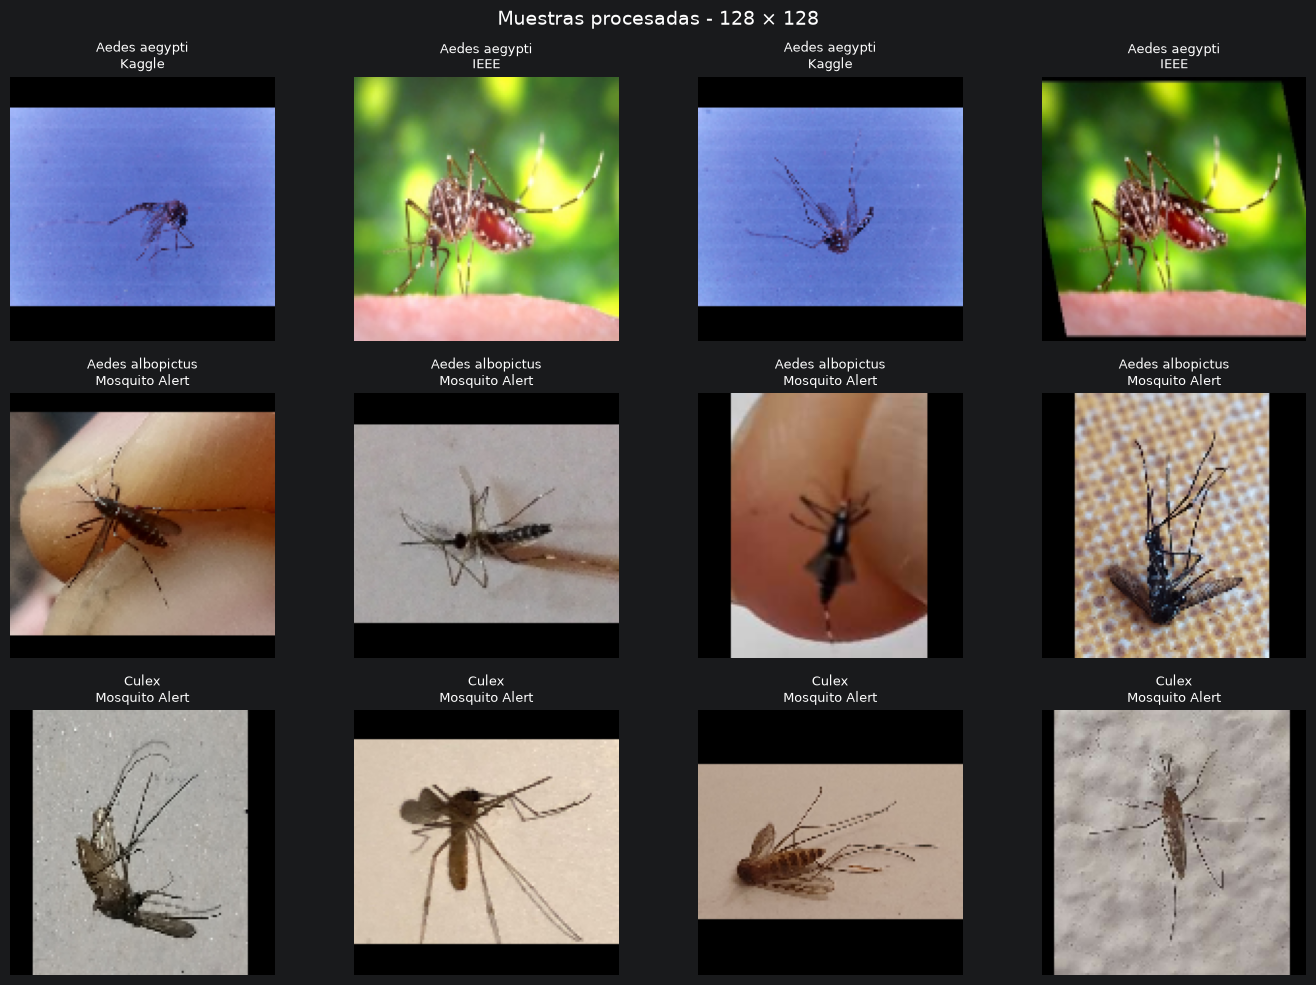

In [74]:
fig, axes = plt.subplots(
    3,
    4,
    figsize=(14, 10)
)

for fila_ax, clase in enumerate(CLASES):

    candidatos = (
        df_train[
            df_train["class_name"]
            == clase
        ]
        .sample(
            n=min(
                4,
                len(
                    df_train[
                        df_train[
                            "class_name"
                        ] == clase
                    ]
                )
            ),
            random_state=SEED
        )
    )

    for columna_ax, (_, fila) in enumerate(
        candidatos.iterrows()
    ):

        ax = axes[
            fila_ax,
            columna_ax
        ]

        imagen = preparar_imagen_fila(
            fila,
            aplicar_bbox=True
        )

        imagen_plot = np.clip(
            imagen.numpy(),
            0,
            255
        ).astype(np.uint8)

        ax.imshow(
            imagen_plot
        )

        ax.set_title(
            f"{clase}\n"
            f"{fila['source_dataset']}",
            fontsize=9
        )

        ax.axis("off")

plt.suptitle(
    "Muestras procesadas - 128 × 128",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Verificar etiquetas numéricas

In [75]:
CLASES = [
    "Aedes aegypti",
    "Aedes albopictus",
    "Culex"
]

CLASS_TO_ID = {
    "Aedes aegypti": 0,
    "Aedes albopictus": 1,
    "Culex": 2
}

for datos in [
    df_train,
    df_val,
    df_test
]:
    datos["class_id"] = (
        datos["class_name"]
        .map(CLASS_TO_ID)
        .astype("int32")
    )

assert df_train["class_id"].notna().all()
assert df_val["class_id"].notna().all()
assert df_test["class_id"].notna().all()

display(
    df_train[
        ["class_name", "class_id"]
    ]
    .drop_duplicates()
    .sort_values("class_id")
)

print("✅ Etiquetas verificadas.")

,class_name,class_id
8,Aedes aegypti,0
3,Aedes albopictus,1
0,Culex,2


✅ Etiquetas verificadas.


## Función generadora

In [76]:
def generador_desde_dataframe(dataframe):

    datos = dataframe.reset_index(
        drop=True
    )

    for _, fila in datos.iterrows():

        imagen = preparar_imagen_fila(
            fila,
            aplicar_bbox=True
        )

        etiqueta = np.int32(
            fila["class_id"]
        )

        yield (
            imagen.numpy(),
            etiqueta
        )

## Crear función tf.data.Dataset

Crear un `tf.data.Dataset` significa **preparar tus datos en un formato que TensorFlow pueda procesar de manera eficiente**, especialmente durante el entrenamiento de un modelo.

En tu proyecto de clasificación de mosquitos con una CNN, normalmente sirve para organizar **imágenes + etiquetas** y alimentar el modelo por lotes.

Por ejemplo, si tienes:

- `X_train`: imágenes de mosquitos.
- `y_train`: especie correspondiente a cada imagen.

In [77]:
def crear_dataset(
    dataframe,
    shuffle=False
):

    dataset = (
        tf.data.Dataset
        .from_generator(
            lambda: generador_desde_dataframe(
                dataframe
            ),
            output_signature=(
                tf.TensorSpec(
                    shape=(
                        IMG_HEIGHT,
                        IMG_WIDTH,
                        3
                    ),
                    dtype=tf.float32
                ),
                tf.TensorSpec(
                    shape=(),
                    dtype=tf.int32
                )
            )
        )
    )

    if shuffle:

        dataset = dataset.shuffle(
            buffer_size=min(
                len(dataframe),
                4000
            ),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

## Crear train, validation y test

In [78]:
train_ds = crear_dataset(
    df_train,
    shuffle=True
)

val_ds = crear_dataset(
    df_val,
    shuffle=False
)

test_ds = crear_dataset(
    df_test,
    shuffle=False
)

print("✅ Datasets creados.")

✅ Datasets creados.


## Inspeccionar un batch

In [79]:
for imagenes, etiquetas in train_ds.take(1):

    print(
        "Shape imágenes:",
        imagenes.shape
    )

    print(
        "Shape etiquetas:",
        etiquetas.shape
    )

    print(
        "Tipo imágenes:",
        imagenes.dtype
    )

    print(
        "Tipo etiquetas:",
        etiquetas.dtype
    )

    print(
        "Píxel mínimo:",
        float(tf.reduce_min(imagenes))
    )

    print(
        "Píxel máximo:",
        float(tf.reduce_max(imagenes))
    )

    print(
        "Etiquetas del batch:",
        etiquetas.numpy()
    )

Shape imágenes: (32, 128, 128, 3)
Shape etiquetas: (32,)
Tipo imágenes: <dtype: 'float32'>
Tipo etiquetas: <dtype: 'int32'>
Píxel mínimo: 0.0
Píxel máximo: 255.0
Etiquetas del batch: [0 1 2 2 2 1 1 2 1 1 0 0 1 1 2 2 1 1 2 0 1 1 2 2 0 1 0 2 1 2 2 1]


## Verificar las tres clases en train_ds

In [80]:
conteo_train = (
    df_train["class_id"]
    .value_counts()
    .sort_index()
)

for class_id in range(NUM_CLASES):

    print(
        class_id,
        "-",
        ID_TO_CLASS[class_id],
        ":",
        int(
            conteo_train.get(
                class_id,
                0
            )
        )
    )

assert set(
    df_train["class_id"].unique()
) == {0, 1, 2}

print(
    "\n✅ Las tres clases están "
    "presentes en entrenamiento."
)

0 - Aedes aegypti : 2225
1 - Aedes albopictus : 3247
2 - Culex : 3562

✅ Las tres clases están presentes en entrenamiento.


## Calcular class_weight

In [83]:
from sklearn.utils.class_weight import compute_class_weight

# Clases numéricas utilizadas por el modelo
clases_presentes = np.array(
    [0, 1, 2],
    dtype=np.int32
)

# Calcular pesos utilizando SOLO el conjunto de entrenamiento
pesos = compute_class_weight(
    class_weight="balanced",
    classes=clases_presentes,
    y=df_train["class_id"].to_numpy()
)

# Convertir a diccionario para Keras
class_weights = {
    int(clase): float(peso)
    for clase, peso in zip(
        clases_presentes,
        pesos
    )
}

print("=" * 60)
print("CLASS WEIGHTS - SOLO TRAIN")
print("=" * 60)

for class_id, peso in class_weights.items():
    print(
        f"{class_id} - "
        f"{ID_TO_CLASS[class_id]}: "
        f"{peso:.4f}"
    )

print("\nDistribución de imágenes en train:")

for class_id in clases_presentes:
    cantidad = int(
        (
            df_train["class_id"]
            == class_id
        ).sum()
    )

    print(
        f"{class_id} - "
        f"{ID_TO_CLASS[class_id]}: "
        f"{cantidad}"
    )

assert set(class_weights.keys()) == {0, 1, 2}

assert all(
    peso > 0
    for peso in class_weights.values()
)

print(
    "\n✅ Class weights calculados correctamente."
)

CLASS WEIGHTS - SOLO TRAIN
0 - Aedes aegypti: 1.3534
1 - Aedes albopictus: 0.9274
2 - Culex: 0.8454

Distribución de imágenes en train:
0 - Aedes aegypti: 2225
1 - Aedes albopictus: 3247
2 - Culex: 3562

✅ Class weights calculados correctamente.


## Crear data augmentation

- `RandomFlip`: cambia orientación horizontal.
- `RandomRotation(0.05)`: rotación moderada.
- `RandomZoom(0.10)`: variación de escala.
- `RandomContrast(0.10)`: reduce dependencia de condiciones lumínicas.

In [85]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip(
            "horizontal"
        ),

        layers.RandomRotation(
            0.05
        ),

        layers.RandomZoom(
            0.10
        ),

        layers.RandomContrast(
            0.10
        )
    ],
    name="data_augmentation"
)

## Visualizar augmentation

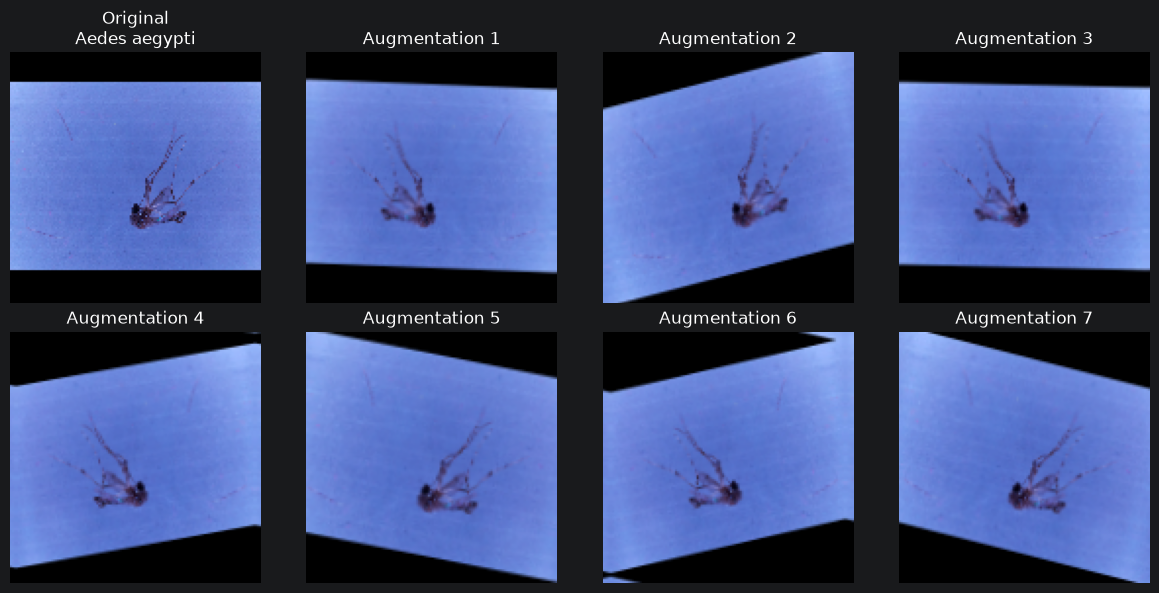

In [87]:
for imagenes, etiquetas in train_ds.take(1):

    imagen_original = imagenes[0]

    clase = ID_TO_CLASS[
        int(etiquetas[0])
    ]

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(12, 6)
    )

    axes = axes.ravel()

    axes[0].imshow(
        np.clip(
            imagen_original.numpy(),
            0,
            255
        ).astype(np.uint8)
    )

    axes[0].set_title(
        f"Original\n{clase}"
    )

    axes[0].axis("off")

    for indice in range(1, 8):

        aumentada = data_augmentation(
            tf.expand_dims(
                imagen_original,
                axis=0
            ),
            training=True
        )[0]

        axes[indice].imshow(
            np.clip(
                aumentada.numpy(),
                0,
                255
            ).astype(np.uint8)
        )

        axes[indice].set_title(
            f"Augmentation {indice}"
        )

        axes[indice].axis("off")

    plt.tight_layout()
    plt.show()

    break

## Construir la CNN propia obligatoria

#### `Conv2D(32)` → `MaxPool` → `Conv2D(64)` → `MaxPool` → `Conv2D(128)` → `MaxPool` → `GlobalAvgPool` → `Dense(128)` → `Dropout(0.5)` → `Softmax(3)`

In [88]:
cnn_propia = keras.Sequential(
    [
        layers.Input(
            shape=(
                IMG_HEIGHT,
                IMG_WIDTH,
                3
            )
        ),

        # Los datasets entregan valores 0-255.
        layers.Rescaling(
            1.0 / 255.0
        ),

        # Solo actúa durante entrenamiento.
        data_augmentation,

        layers.Conv2D(
            32,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),

        layers.MaxPooling2D(
            pool_size=(2, 2)
        ),

        layers.Conv2D(
            64,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),

        layers.MaxPooling2D(
            pool_size=(2, 2)
        ),

        layers.Conv2D(
            128,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),

        layers.MaxPooling2D(
            pool_size=(2, 2)
        ),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(
            0.5
        ),

        layers.Dense(
            NUM_CLASES,
            activation="softmax"
        )
    ],
    name="VectorIA_CNN_Propia"
)

cnn_propia.summary()

Model: "VectorIA_CNN_Propia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

## Compilar la CNN

In [89]:
cnn_propia.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=(
        "sparse_categorical_crossentropy"
    ),

    metrics=[
        "accuracy"
    ]
)

print(
    "✅ CNN compilada correctamente."
)

✅ CNN compilada correctamente.


## Crear carpeta de modelos y callbacks

In [90]:
MODELS = (
    PROYECTO
    / "models"
)

MODELS.mkdir(
    parents=True,
    exist_ok=True
)

RUTA_CNN = (
    MODELS
    / "cnn_mosquitos.keras"
)

callbacks_cnn = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(RUTA_CNN),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print(
    "Modelo se guardará en:"
)

print(
    RUTA_CNN
)

Modelo se guardará en:
C:\VectorAI\VectorIA\models\cnn_mosquitos.keras
